# 머신러닝 성능 향상을 위한 특성 공학(Feature Engineering) 파이프라인 설계 및 비교 분석

- **데이터셋**: Kaggle Titanic - Machine Learning from Disaster (`891행 × 12열`)
- **목표**: 탐색적 데이터 분석(EDA)부터 결측치 처리, 범주형 인코딩, 스케일링, 도메인 파생변수 생성, 변수 선택(Feature Selection), 모델 학습·평가 및 설명 가능한 AI(SHAP/LIME)·AutoML 비교까지 전체 ML 파이프라인을 누수 없이(Leak-free) 구현하고 성능을 정량 비교한다.

## STEP 01. 데이터 준비 (Data Preparation)

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.utils import configure_korean_font, DATA_DIR, RESULTS_DIR, FIG_DIR

configure_korean_font()
df = pd.read_csv(DATA_DIR / 'titanic.csv')
print(f'데이터셋 Shape: {df.shape} (행: {df.shape[0]}, 열: {df.shape[1]})')
display(df.head())

col_summary = pd.read_csv(RESULTS_DIR / 'step01_column_summary.csv')
display(col_summary)

데이터셋 Shape: (891, 12) (행: 891, 열: 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,컬럼명,데이터 유형,실제 dtype,결측치 수(비율),고유값 수,예시 값,설명 및 전처리 방향
0,PassengerId,수치형 (ID),int64,0 (0.00%),891,"1, 2, 3",승객 고유 식별 번호 (1 ~ 891) / 식별자 (모델 학습 제외)
1,Survived,범주형 (이진 타겟),int64,0 (0.00%),2,"0, 1","생존 여부 (0 = 사망, 1 = 생존) / 타겟 변수 (Target)"
2,Pclass,범주형 (순서형),int64,0 (0.00%),3,"3, 1, 2","객실 등급 (1 = 1등석, 2 = 2등석, 3 = 3등석) / 사회·경제적 지위 ..."
3,Name,텍스트 (범주형),str,0 (0.00%),891,"Braund, Mr. Owen Harris, Cumings, Mrs. John Br...","승객 성명 및 사회적 호칭(Mr, Mrs, Miss 등) 포함 / 파생변수 Titl..."
4,Sex,범주형 (명목형),str,0 (0.00%),2,"male, female","성별 (male, female) / 핵심 예측 변수"
5,Age,수치형 (연속형),float64,177 (19.87%),88,"22.0, 38.0, 26.0","승객 나이 (세, 유아는 소수점 표기) / 약 19.87% 결측 존재"
6,SibSp,수치형 (이산형),int64,0 (0.00%),7,"1, 0, 3",동승한 형제자매 및 배우자 수 / 가족 규모 파생에 활용
7,Parch,수치형 (이산형),int64,0 (0.00%),7,"0, 1, 2",동승한 부모 및 자녀 수 / 가족 규모 파생에 활용
8,Ticket,텍스트 (범주형),str,0 (0.00%),681,"A/5 21171, PC 17599, STON/O2. 3101282",티켓 고유 번호 (681개 고유값) / 고카디널리티 변수 (제거)
9,Fare,수치형 (연속형),float64,0 (0.00%),248,"7.25, 71.2833, 7.925","지불 운임 요금 (영국 파운드, £) / 우측 편향(왜도) 및 이상치 존재"


## STEP 02. 탐색적 데이터 분석 (EDA)
- 결측치 비율 분석 (`Cabin` 77.10%, `Age` 19.87%, `Embarked` 0.22%)
- IQR 기반 수치형 이상치 탐색 (`Fare` 우측 왜도 4.79)
- 필수 시각화 4종: Histogram, Boxplot, Correlation Heatmap, Countplot/Barplot

,변수명,유효 샘플 수,평균,중앙값,표준편차,왜도(Skewness),Q1 / Q3,IQR 정상 범위,이상치 개수(비율),최댓값
0,Age,714,29.70,28.00,14.53,0.39,20.12 / 38.00,"[-6.69, 64.81]",11 (1.54%),80.00
1,SibSp,891,0.52,0.00,1.10,3.70,0.00 / 1.00,"[-1.50, 2.50]",46 (5.16%),8.00
2,Parch,891,0.38,0.00,0.81,2.75,0.00 / 0.00,"[0.00, 0.00]",213 (23.91%),6.00
3,Fare,891,32.20,14.45,49.69,4.79,7.91 / 31.00,"[-26.72, 65.63]",116 (13.02%),512.33


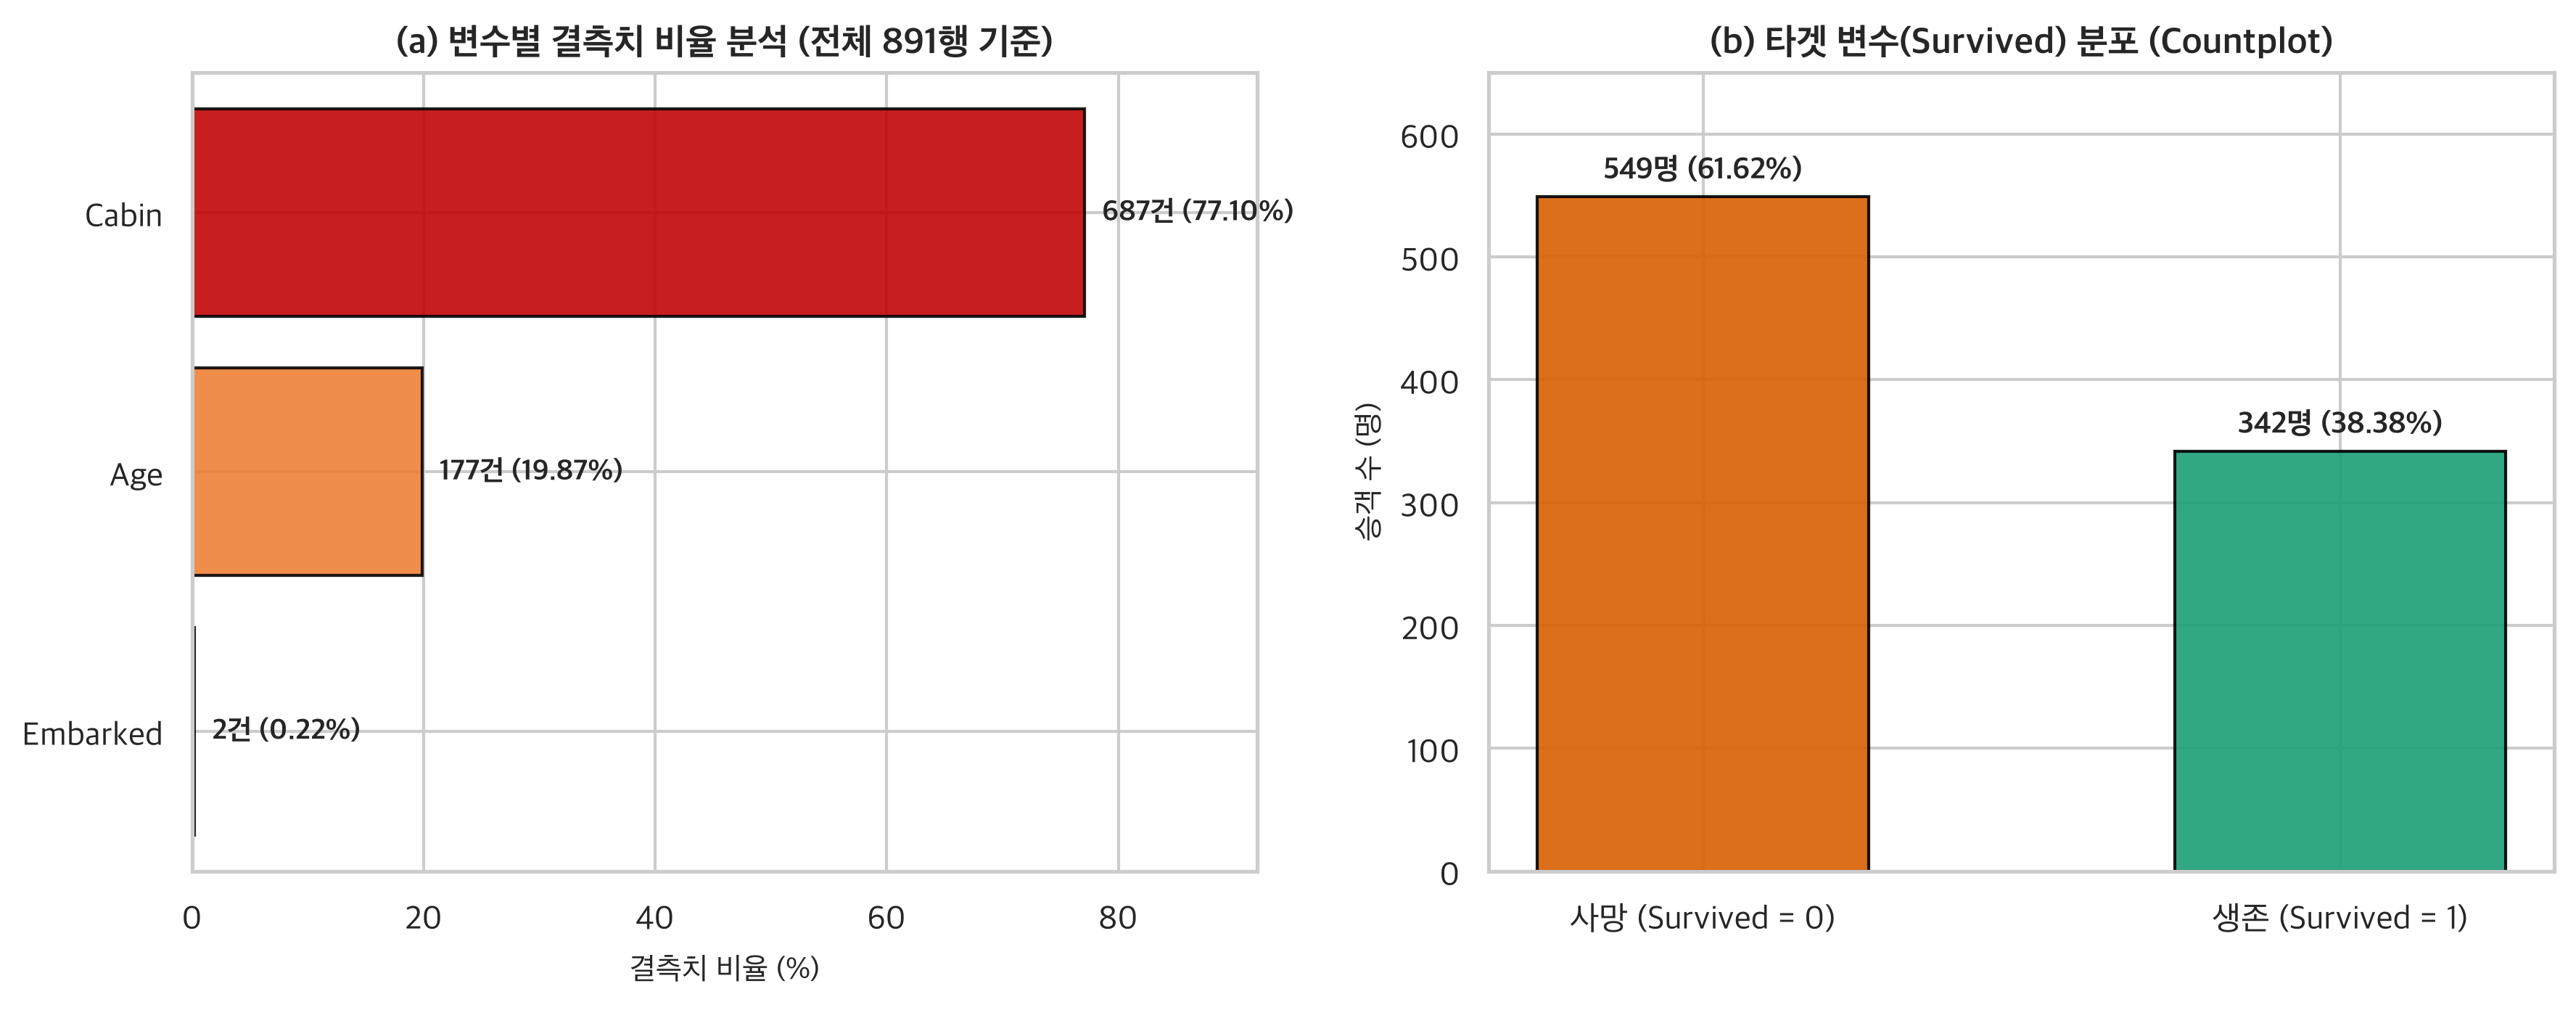

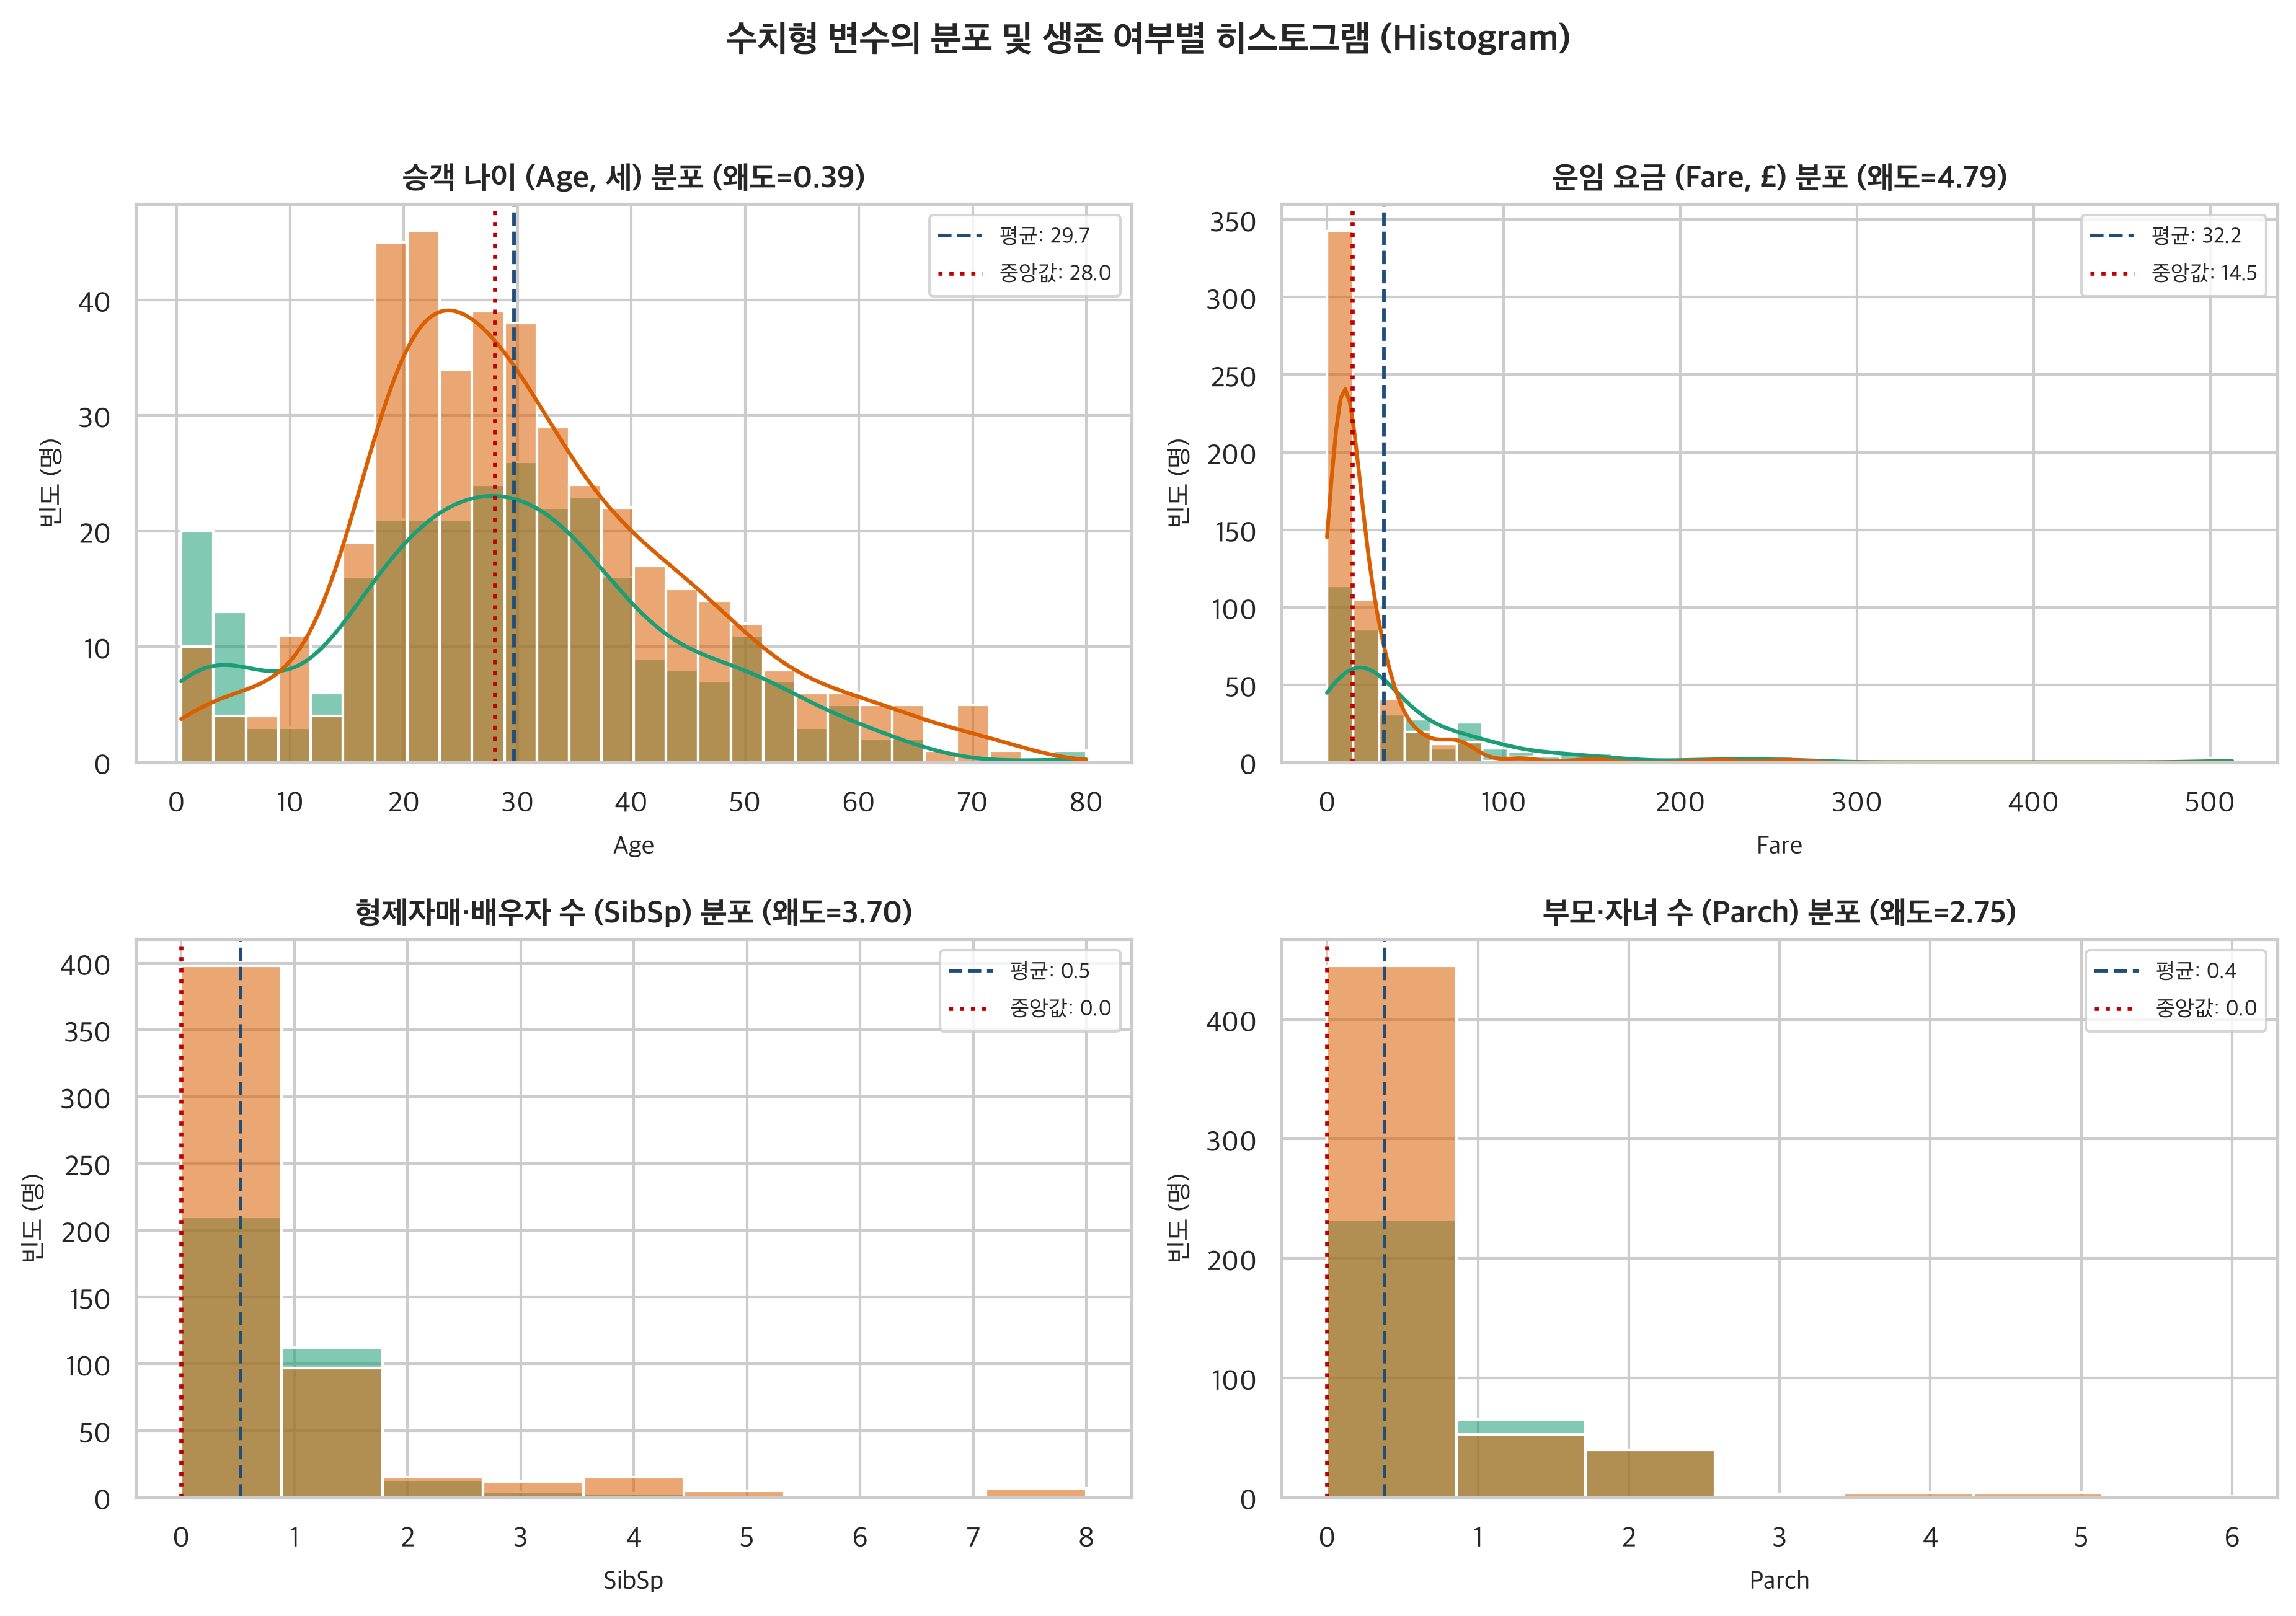

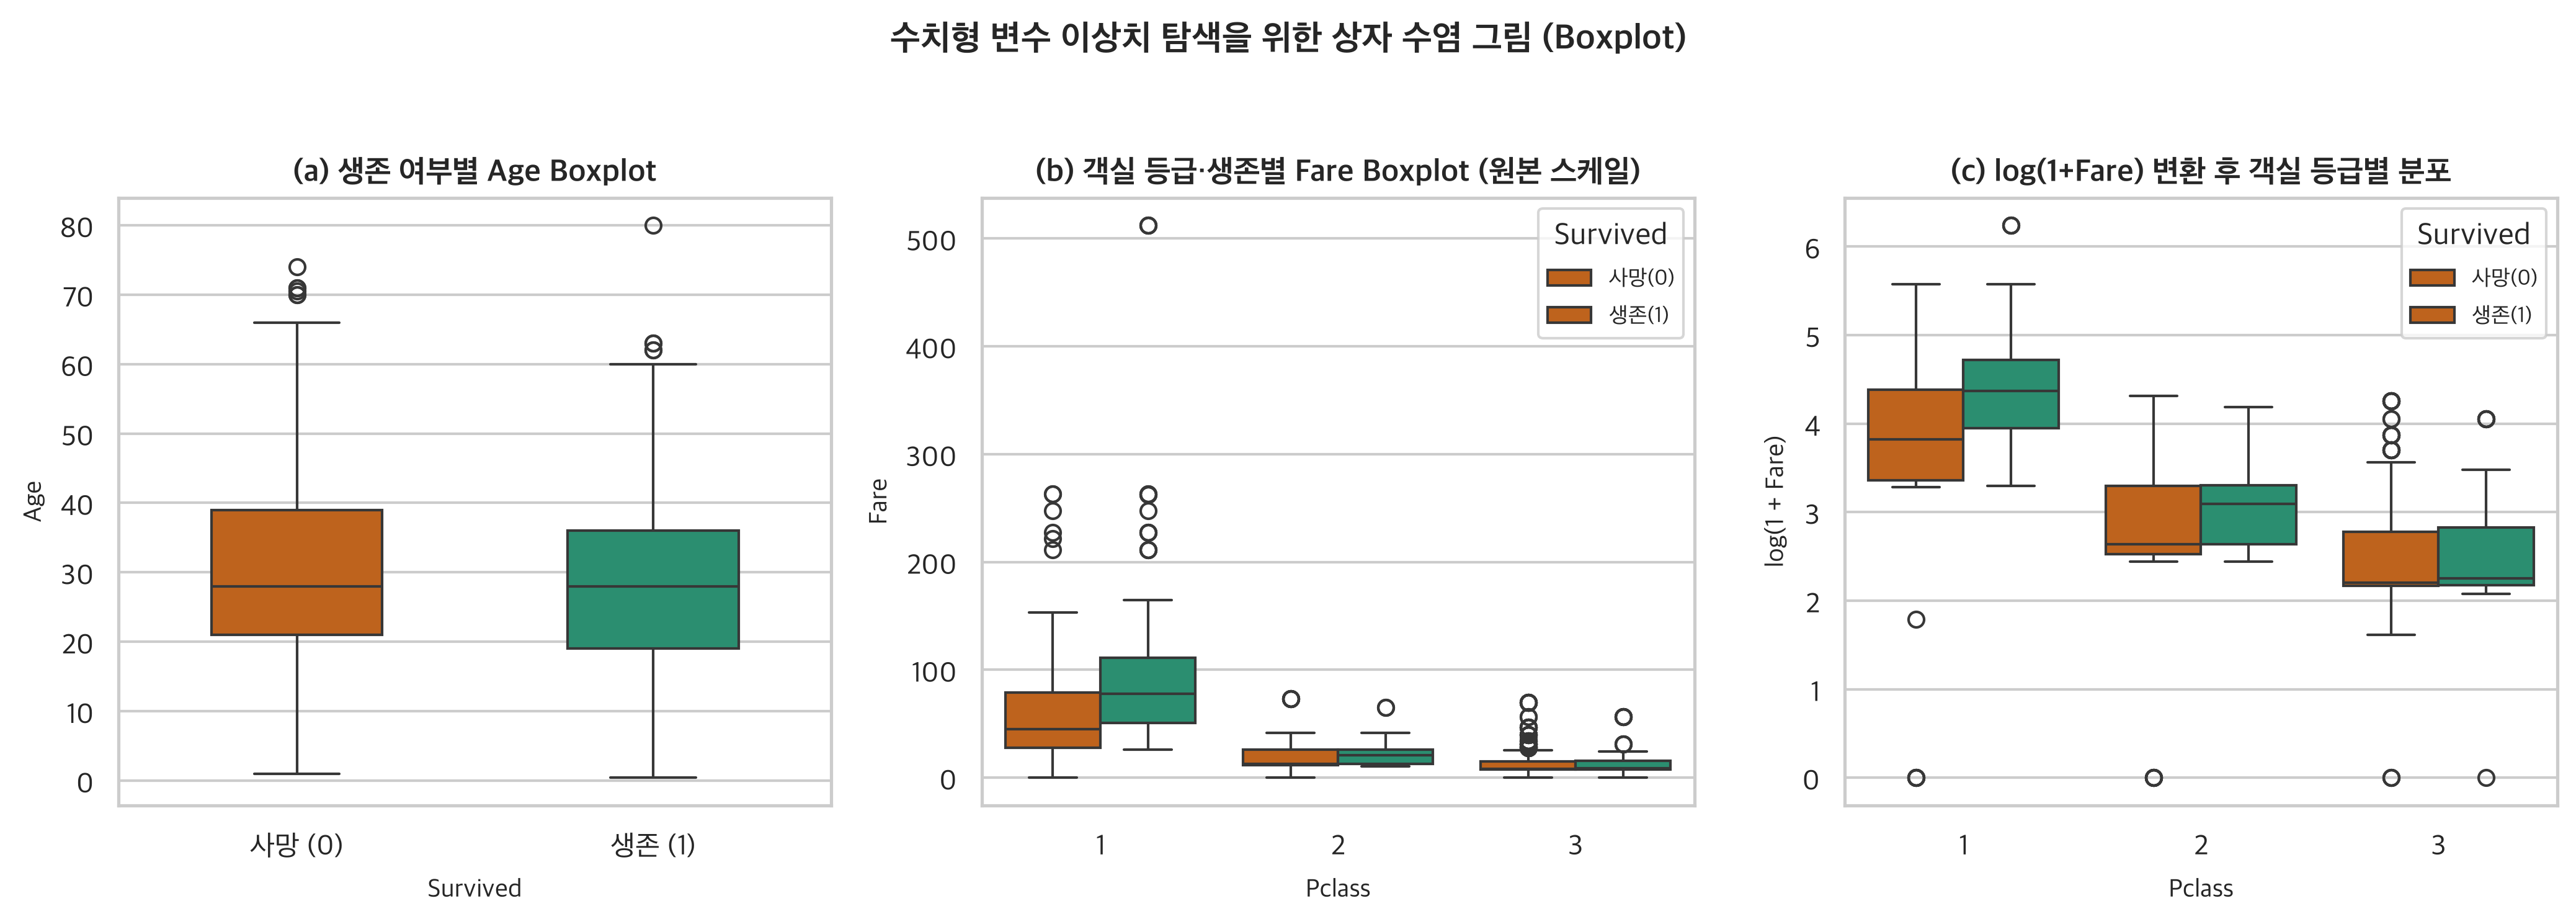

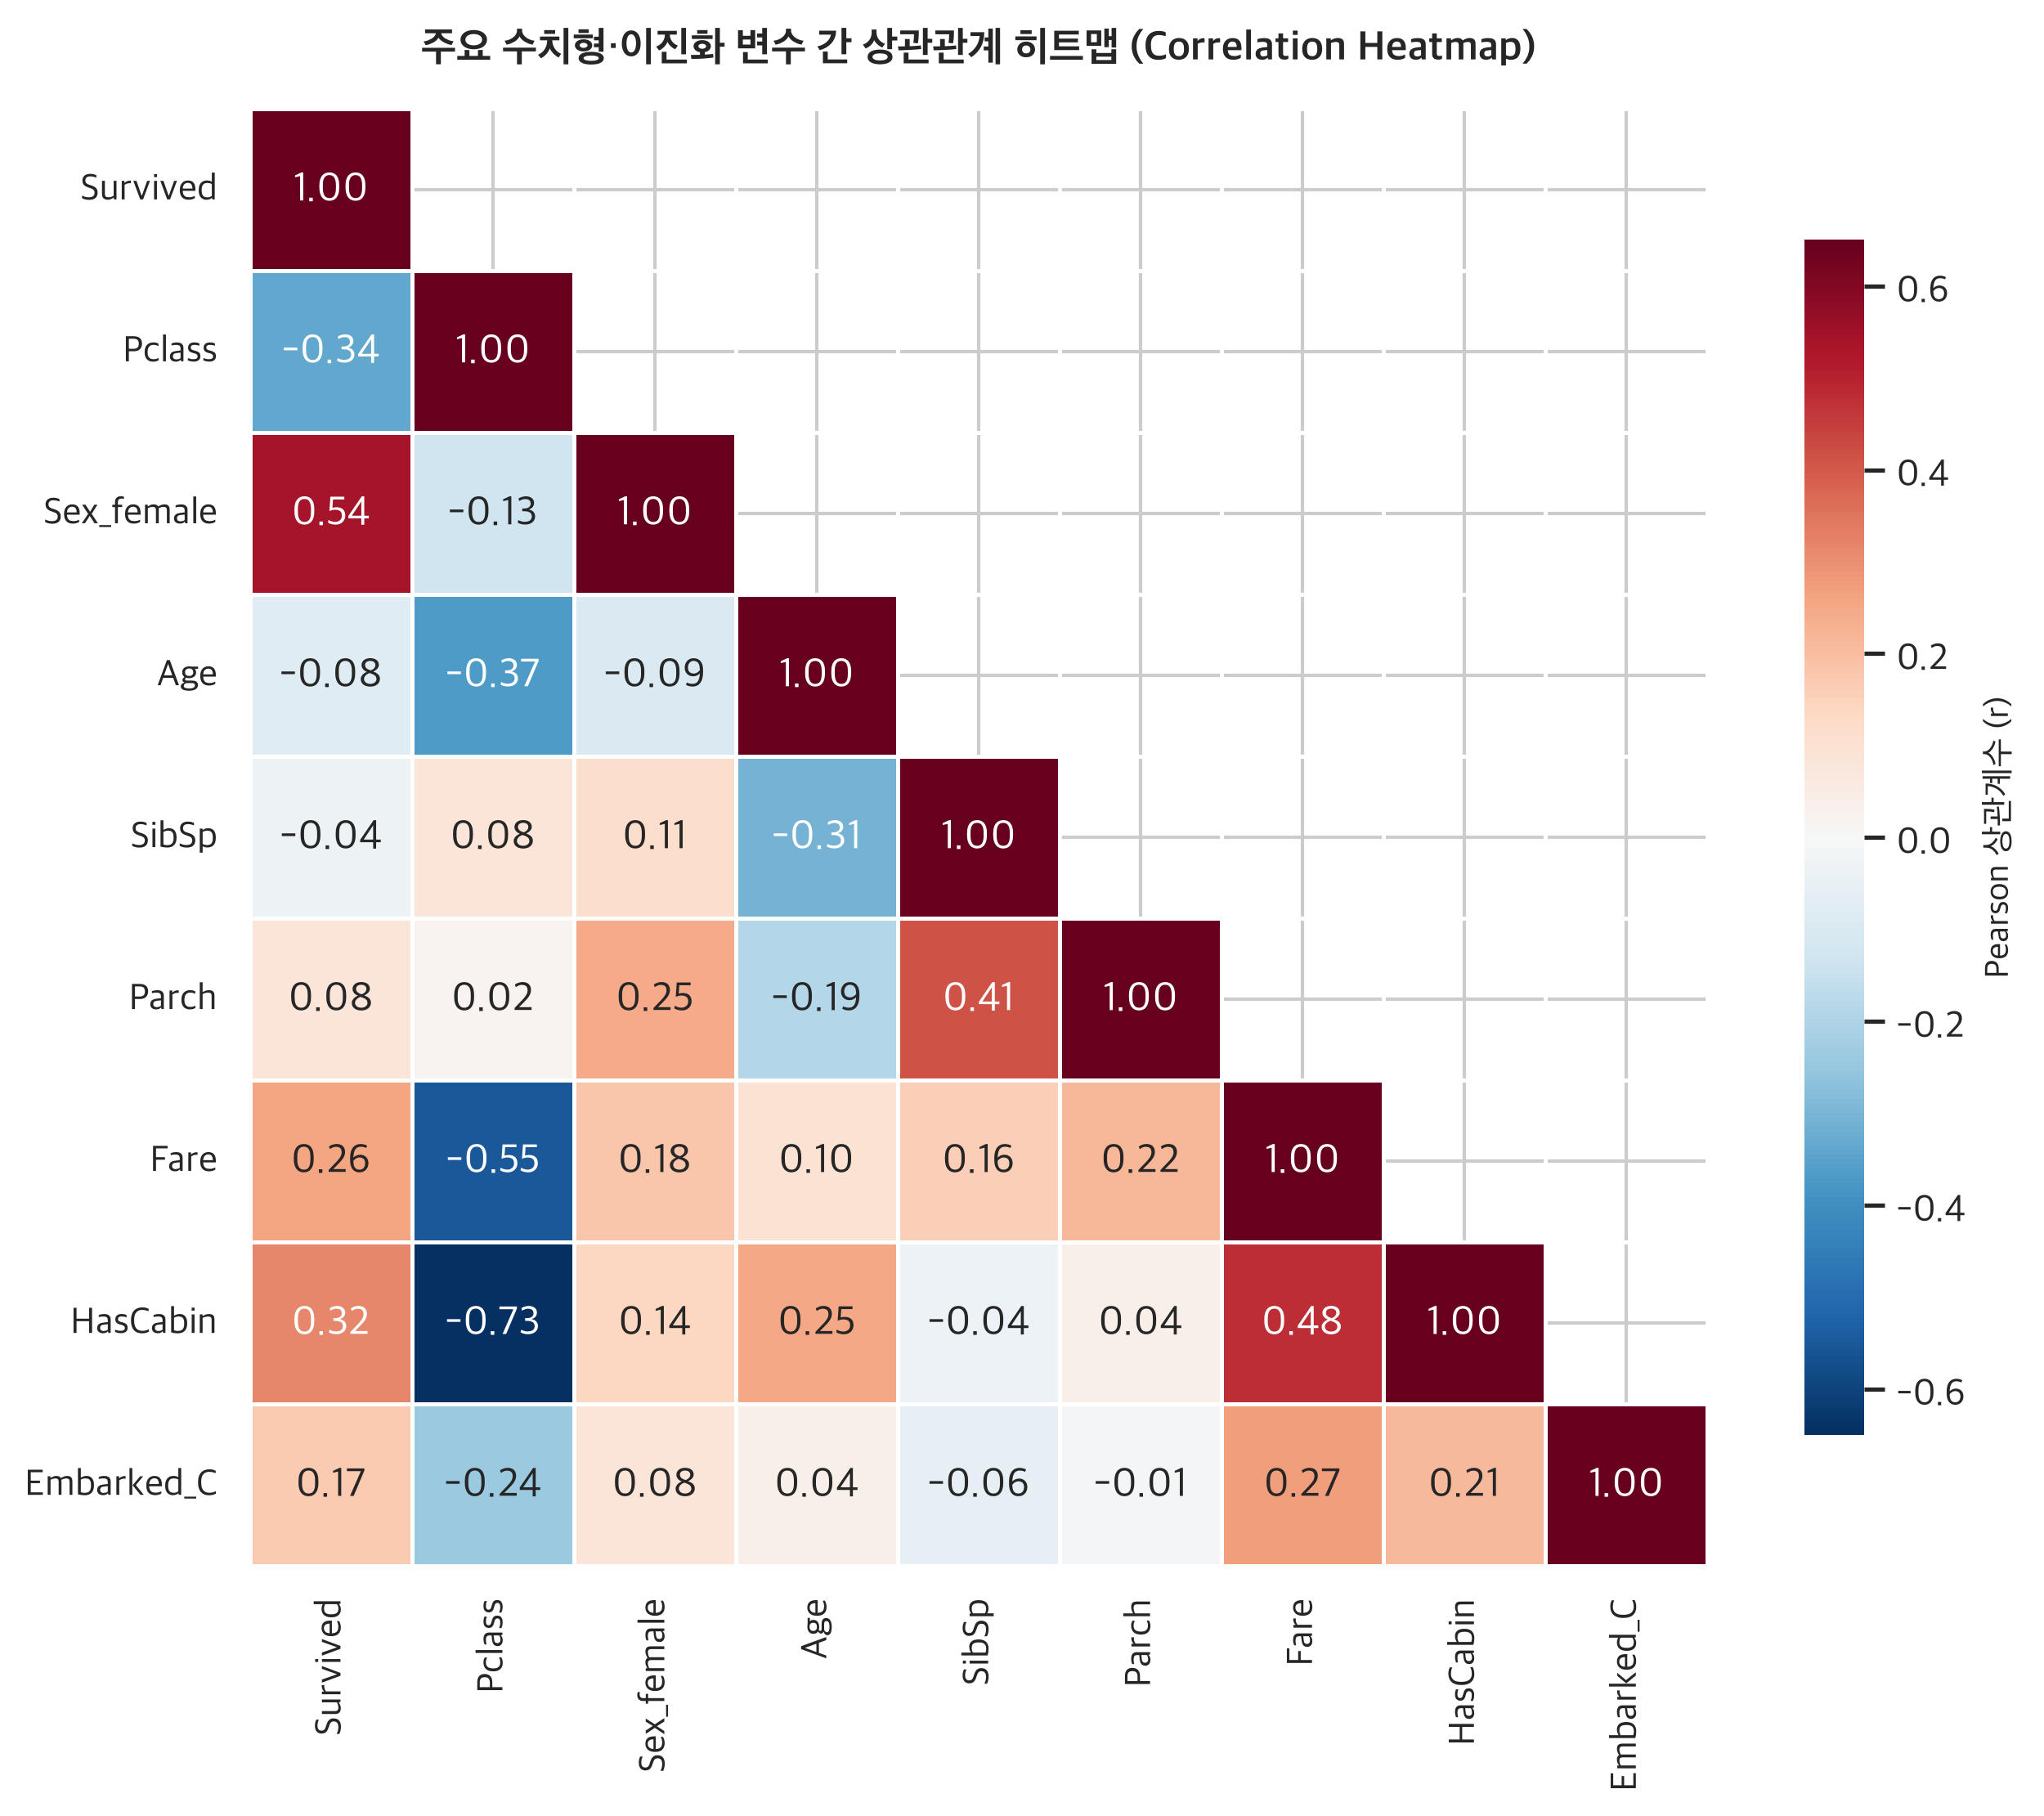

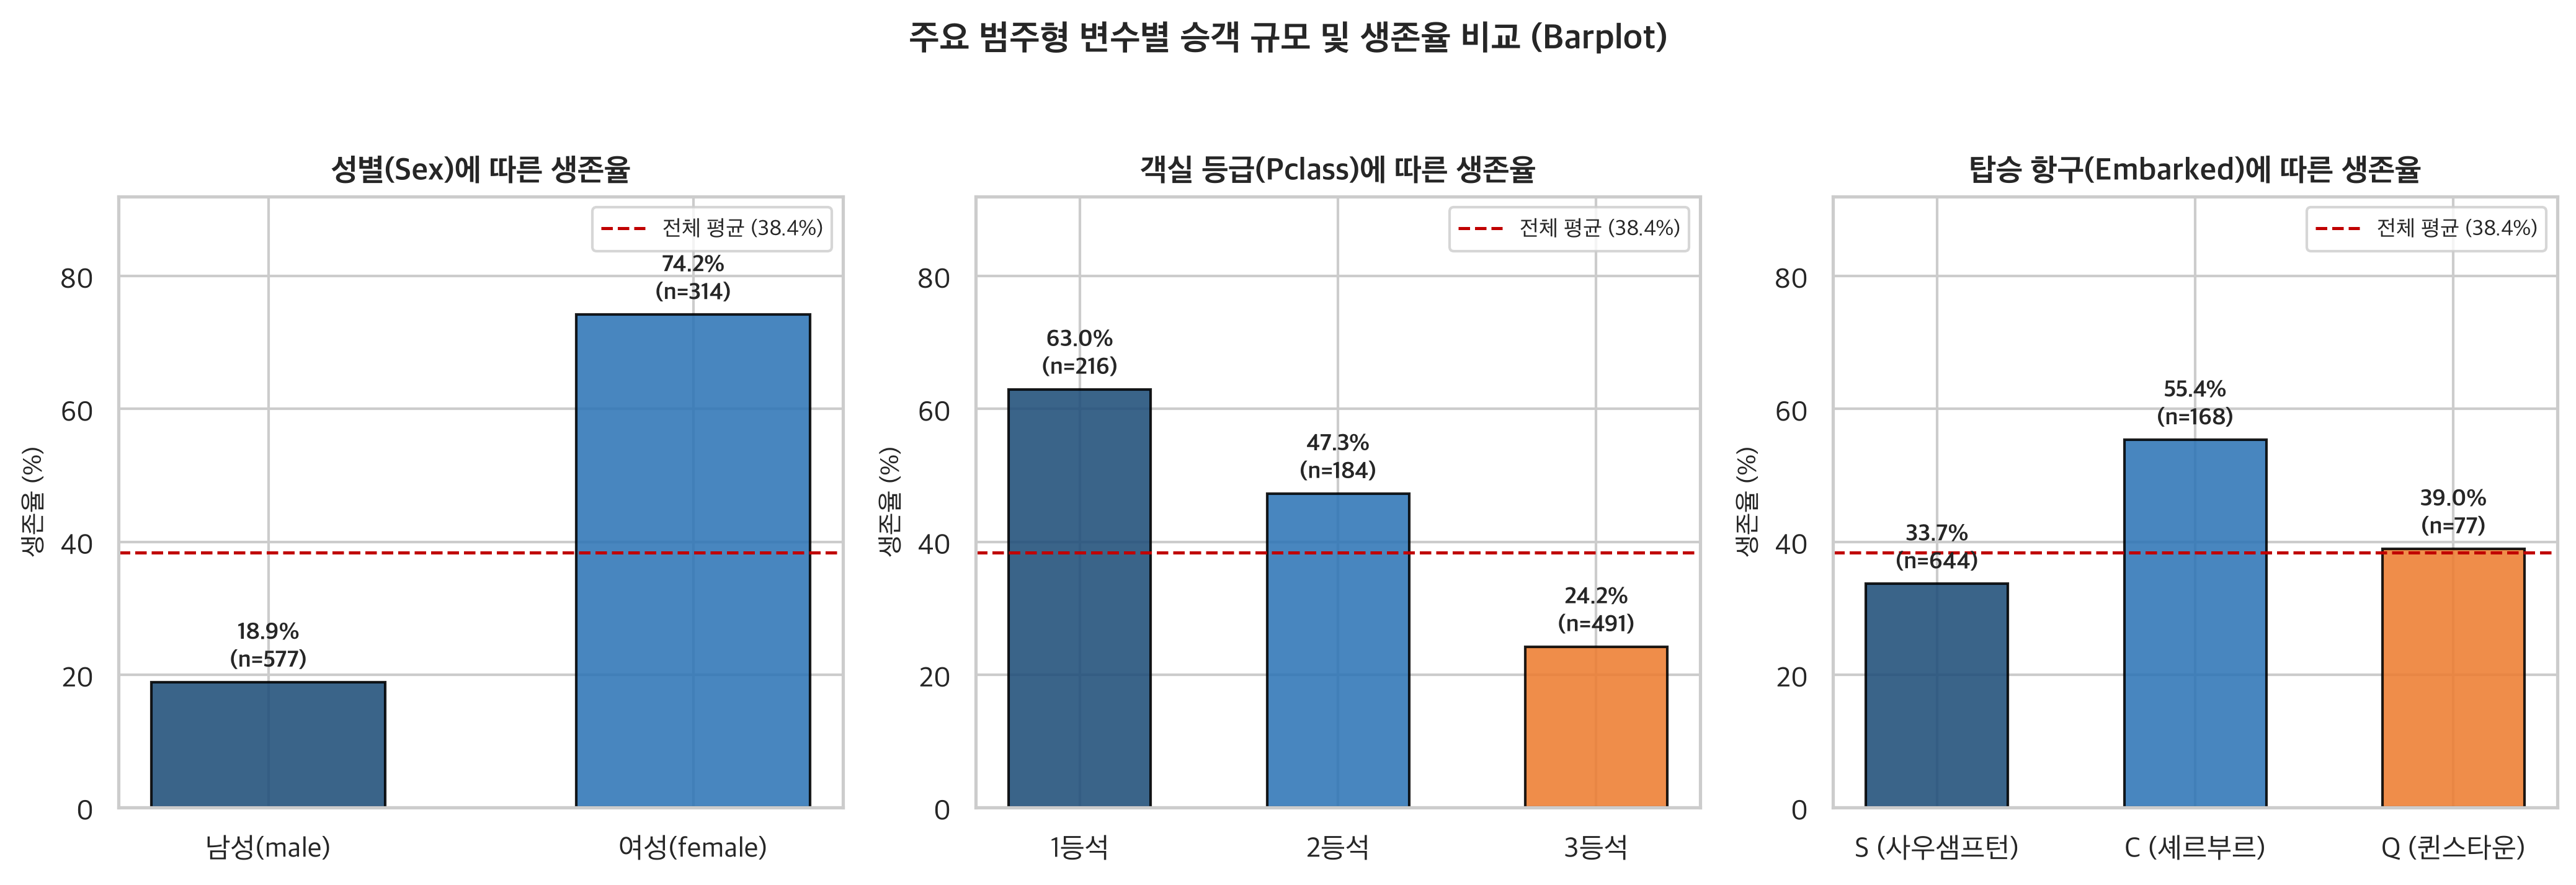

In [2]:
outlier_summary = pd.read_csv(RESULTS_DIR / 'step02_outlier_summary.csv')
display(outlier_summary)
for fig_name in [
    'fig01_missing_and_target.png',
    'fig02_histograms.png',
    'fig03_boxplots.png',
    'fig04_correlation_heatmap.png',
    'fig05_categorical_bars.png',
]:
    display(Image(filename=str(FIG_DIR / fig_name), width=820))

## STEP 03. 특성 공학 파이프라인 구현 및 전략별 비교 실험
- `sklearn.pipeline.Pipeline` + `ColumnTransformer` + 커스텀 `TitanicFeatureEngineer`를 결합하여 교차검증 폴드 내 데이터 누수(Data Leakage) 원천 차단
- **3-1 결측치 처리 비교**: Drop NA, Mean, Median, Most Frequent, Group-Median(`Pclass×Sex`)
- **3-2 범주형 인코딩 비교**: Label(Ordinal), One-Hot, Target Encoding
- **3-3 스케일링 비교**: No Scaling, StandardScaler, MinMaxScaler, RobustScaler
- **3-4 파생 변수 생성 (7종)**: `FamilySize`, `IsAlone`, `FarePerPerson`, `Title`, `HasCabin`, `Deck`, `AgeGroup`

Pipeline(steps=[('group_age', GroupMedianAgeImputer()),
                ('fe', TitanicFeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare',
                                                   'FamilySize', 'IsAlone',
                                                   'FarePerPerson',
                                                   'HasCabin']),
                                                 ('cat',
                                                  Pipeline

,전략,샘플 수(Train/Test),모델,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_train_roc_auc_mean,overfit_gap_roc_auc,overfit_gap_accuracy
0,Drop NA (결측 행 제거),573/139,Logistic Regression,0.8129,0.8163,0.7018,0.7547,0.8607,0.7889,0.7484,0.7236,0.7322,0.8521,0.8615,0.0094,0.0061
1,Drop NA (결측 행 제거),573/139,Random Forest,0.8058,0.8409,0.6491,0.7327,0.8430,0.8169,0.8174,0.7104,0.7581,0.8719,0.9610,0.0891,0.0889
2,Drop NA (결측 행 제거),573/139,XGBoost,0.7986,0.8085,0.6667,0.7308,0.8235,0.8082,0.8001,0.7105,0.7482,0.8776,0.9706,0.0930,0.1063
3,Drop NA (결측 행 제거),573/139,LightGBM,0.7698,0.7551,0.6491,0.6981,0.8110,0.8255,0.8270,0.7190,0.7679,0.8716,0.9699,0.0984,0.0903
4,Mean Imputation,712/179,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8451,0.7963,0.7531,0.7034,0.7260,0.8556,0.8606,0.0051,0.0060
5,Mean Imputation,712/179,Random Forest,0.8101,0.8302,0.6377,0.7213,0.8368,0.8118,0.7983,0.6848,0.7361,0.8719,0.9595,0.0877,0.0920
6,Mean Imputation,712/179,XGBoost,0.8101,0.7966,0.6812,0.7344,0.8190,0.8160,0.7997,0.7032,0.7466,0.8817,0.9657,0.0840,0.0895
7,Mean Imputation,712/179,LightGBM,0.7933,0.7759,0.6522,0.7087,0.8051,0.8202,0.8046,0.7068,0.7512,0.8724,0.9678,0.0954,0.0881
8,Median Imputation,712/179,Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8437,0.7963,0.7531,0.7034,0.7260,0.8551,0.8606,0.0054,0.0060
9,Median Imputation,712/179,Random Forest,0.8045,0.8269,0.6232,0.7107,0.8354,0.8118,0.7982,0.6848,0.7362,0.8726,0.9597,0.0871,0.0902



=== [3-2] 범주형 인코딩 비교 ===


,인코딩 전략,모델,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_train_roc_auc_mean,overfit_gap_roc_auc,overfit_gap_accuracy
0,Label (Ordinal) Encoding,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8534,0.8020,0.7544,0.7292,0.7390,0.8554,0.8658,0.0104,0.0161
1,Label (Ordinal) Encoding,Random Forest,0.7989,0.7619,0.6957,0.7273,0.8389,0.8273,0.7975,0.7438,0.7681,0.8848,0.9646,0.0798,0.0860
2,Label (Ordinal) Encoding,XGBoost,0.7877,0.7627,0.6522,0.7031,0.8474,0.8273,0.8033,0.7403,0.7677,0.8935,0.9744,0.0809,0.0951
3,Label (Ordinal) Encoding,LightGBM,0.7877,0.7541,0.6667,0.7077,0.8358,0.8259,0.8014,0.7328,0.7639,0.8857,0.9779,0.0922,0.1011
4,One-Hot Encoding,Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8704,0.8203,0.7701,0.7657,0.7664,0.8671,0.8830,0.0159,0.0154
5,One-Hot Encoding,Random Forest,0.8045,0.7742,0.6957,0.7328,0.8428,0.8245,0.8080,0.7178,0.7589,0.8874,0.9568,0.0694,0.0797
6,One-Hot Encoding,XGBoost,0.7989,0.7705,0.6812,0.7231,0.8470,0.8315,0.8064,0.7475,0.7735,0.8963,0.9754,0.0791,0.0926
7,One-Hot Encoding,LightGBM,0.7933,0.7581,0.6812,0.7176,0.8387,0.8202,0.7895,0.7292,0.7569,0.8885,0.9765,0.0880,0.1039
8,Target Encoding,Logistic Regression,0.8101,0.7536,0.7536,0.7536,0.8684,0.8174,0.7655,0.7620,0.7626,0.8659,0.8738,0.0080,0.0053
9,Target Encoding,Random Forest,0.8101,0.7778,0.7101,0.7424,0.8445,0.8357,0.8187,0.7438,0.7771,0.8850,0.9495,0.0645,0.0635



=== [3-3] 스케일링 비교 ===


,스케일링 전략,모델,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_train_roc_auc_mean,overfit_gap_roc_auc,overfit_gap_accuracy
0,No Scaling (원본),Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8706,0.8189,0.7680,0.7657,0.7651,0.8674,0.8828,0.0154,0.0158
1,No Scaling (원본),Random Forest,0.8045,0.7742,0.6957,0.7328,0.8439,0.8231,0.8044,0.7178,0.7574,0.8870,0.9568,0.0698,0.0814
2,No Scaling (원본),XGBoost,0.7989,0.7705,0.6812,0.7231,0.8470,0.8315,0.8064,0.7475,0.7735,0.8963,0.9754,0.0791,0.0926
3,No Scaling (원본),LightGBM,0.7877,0.7627,0.6522,0.7031,0.8360,0.8160,0.7803,0.7292,0.7526,0.8879,0.9765,0.0886,0.1085
4,StandardScaler,Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8704,0.8203,0.7701,0.7657,0.7664,0.8671,0.8830,0.0159,0.0154
5,StandardScaler,Random Forest,0.8045,0.7742,0.6957,0.7328,0.8428,0.8245,0.8080,0.7178,0.7589,0.8874,0.9568,0.0694,0.0797
6,StandardScaler,XGBoost,0.7989,0.7705,0.6812,0.7231,0.8470,0.8315,0.8064,0.7475,0.7735,0.8963,0.9754,0.0791,0.0926
7,StandardScaler,LightGBM,0.7933,0.7581,0.6812,0.7176,0.8387,0.8202,0.7895,0.7292,0.7569,0.8885,0.9765,0.0880,0.1039
8,MinMaxScaler,Logistic Regression,0.8268,0.7879,0.7536,0.7704,0.8663,0.8217,0.7667,0.7768,0.7703,0.8717,0.8838,0.0121,0.0168
9,MinMaxScaler,Random Forest,0.8045,0.7742,0.6957,0.7328,0.8435,0.8231,0.8044,0.7178,0.7574,0.8870,0.9568,0.0698,0.0811



=== [3-4] 파생변수 생성 전/후 비교 ===


,파생변수 여부,모델,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_train_roc_auc_mean,overfit_gap_roc_auc,overfit_gap_accuracy
0,파생변수 생성 전 (원본 7개 특성),Logistic Regression,0.8045,0.7931,0.6667,0.7244,0.8436,0.7935,0.7514,0.6960,0.7213,0.8551,0.8606,0.0054,0.0088
1,파생변수 생성 전 (원본 7개 특성),Random Forest,0.8045,0.8269,0.6232,0.7107,0.8360,0.8090,0.7961,0.6775,0.7312,0.8720,0.9597,0.0876,0.0941
2,파생변수 생성 전 (원본 7개 특성),XGBoost,0.8045,0.7931,0.6667,0.7244,0.8145,0.8188,0.8071,0.7032,0.7496,0.8814,0.9658,0.0843,0.0867
3,파생변수 생성 전 (원본 7개 특성),LightGBM,0.7989,0.7797,0.6667,0.7188,0.8024,0.8231,0.8111,0.7069,0.7543,0.8728,0.9680,0.0953,0.0821
4,파생변수 생성 후 (+7개 도메인 특성),Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8704,0.8203,0.7701,0.7657,0.7664,0.8671,0.8828,0.0157,0.0154
5,파생변수 생성 후 (+7개 도메인 특성),Random Forest,0.8045,0.7742,0.6957,0.7328,0.8435,0.8245,0.8051,0.7215,0.7598,0.8873,0.9568,0.0696,0.0800
6,파생변수 생성 후 (+7개 도메인 특성),XGBoost,0.7989,0.7705,0.6812,0.7231,0.8470,0.8315,0.8064,0.7475,0.7735,0.8963,0.9754,0.0791,0.0926
7,파생변수 생성 후 (+7개 도메인 특성),LightGBM,0.7933,0.7667,0.6667,0.7132,0.8356,0.8189,0.7905,0.7255,0.7548,0.8887,0.9763,0.0876,0.1053


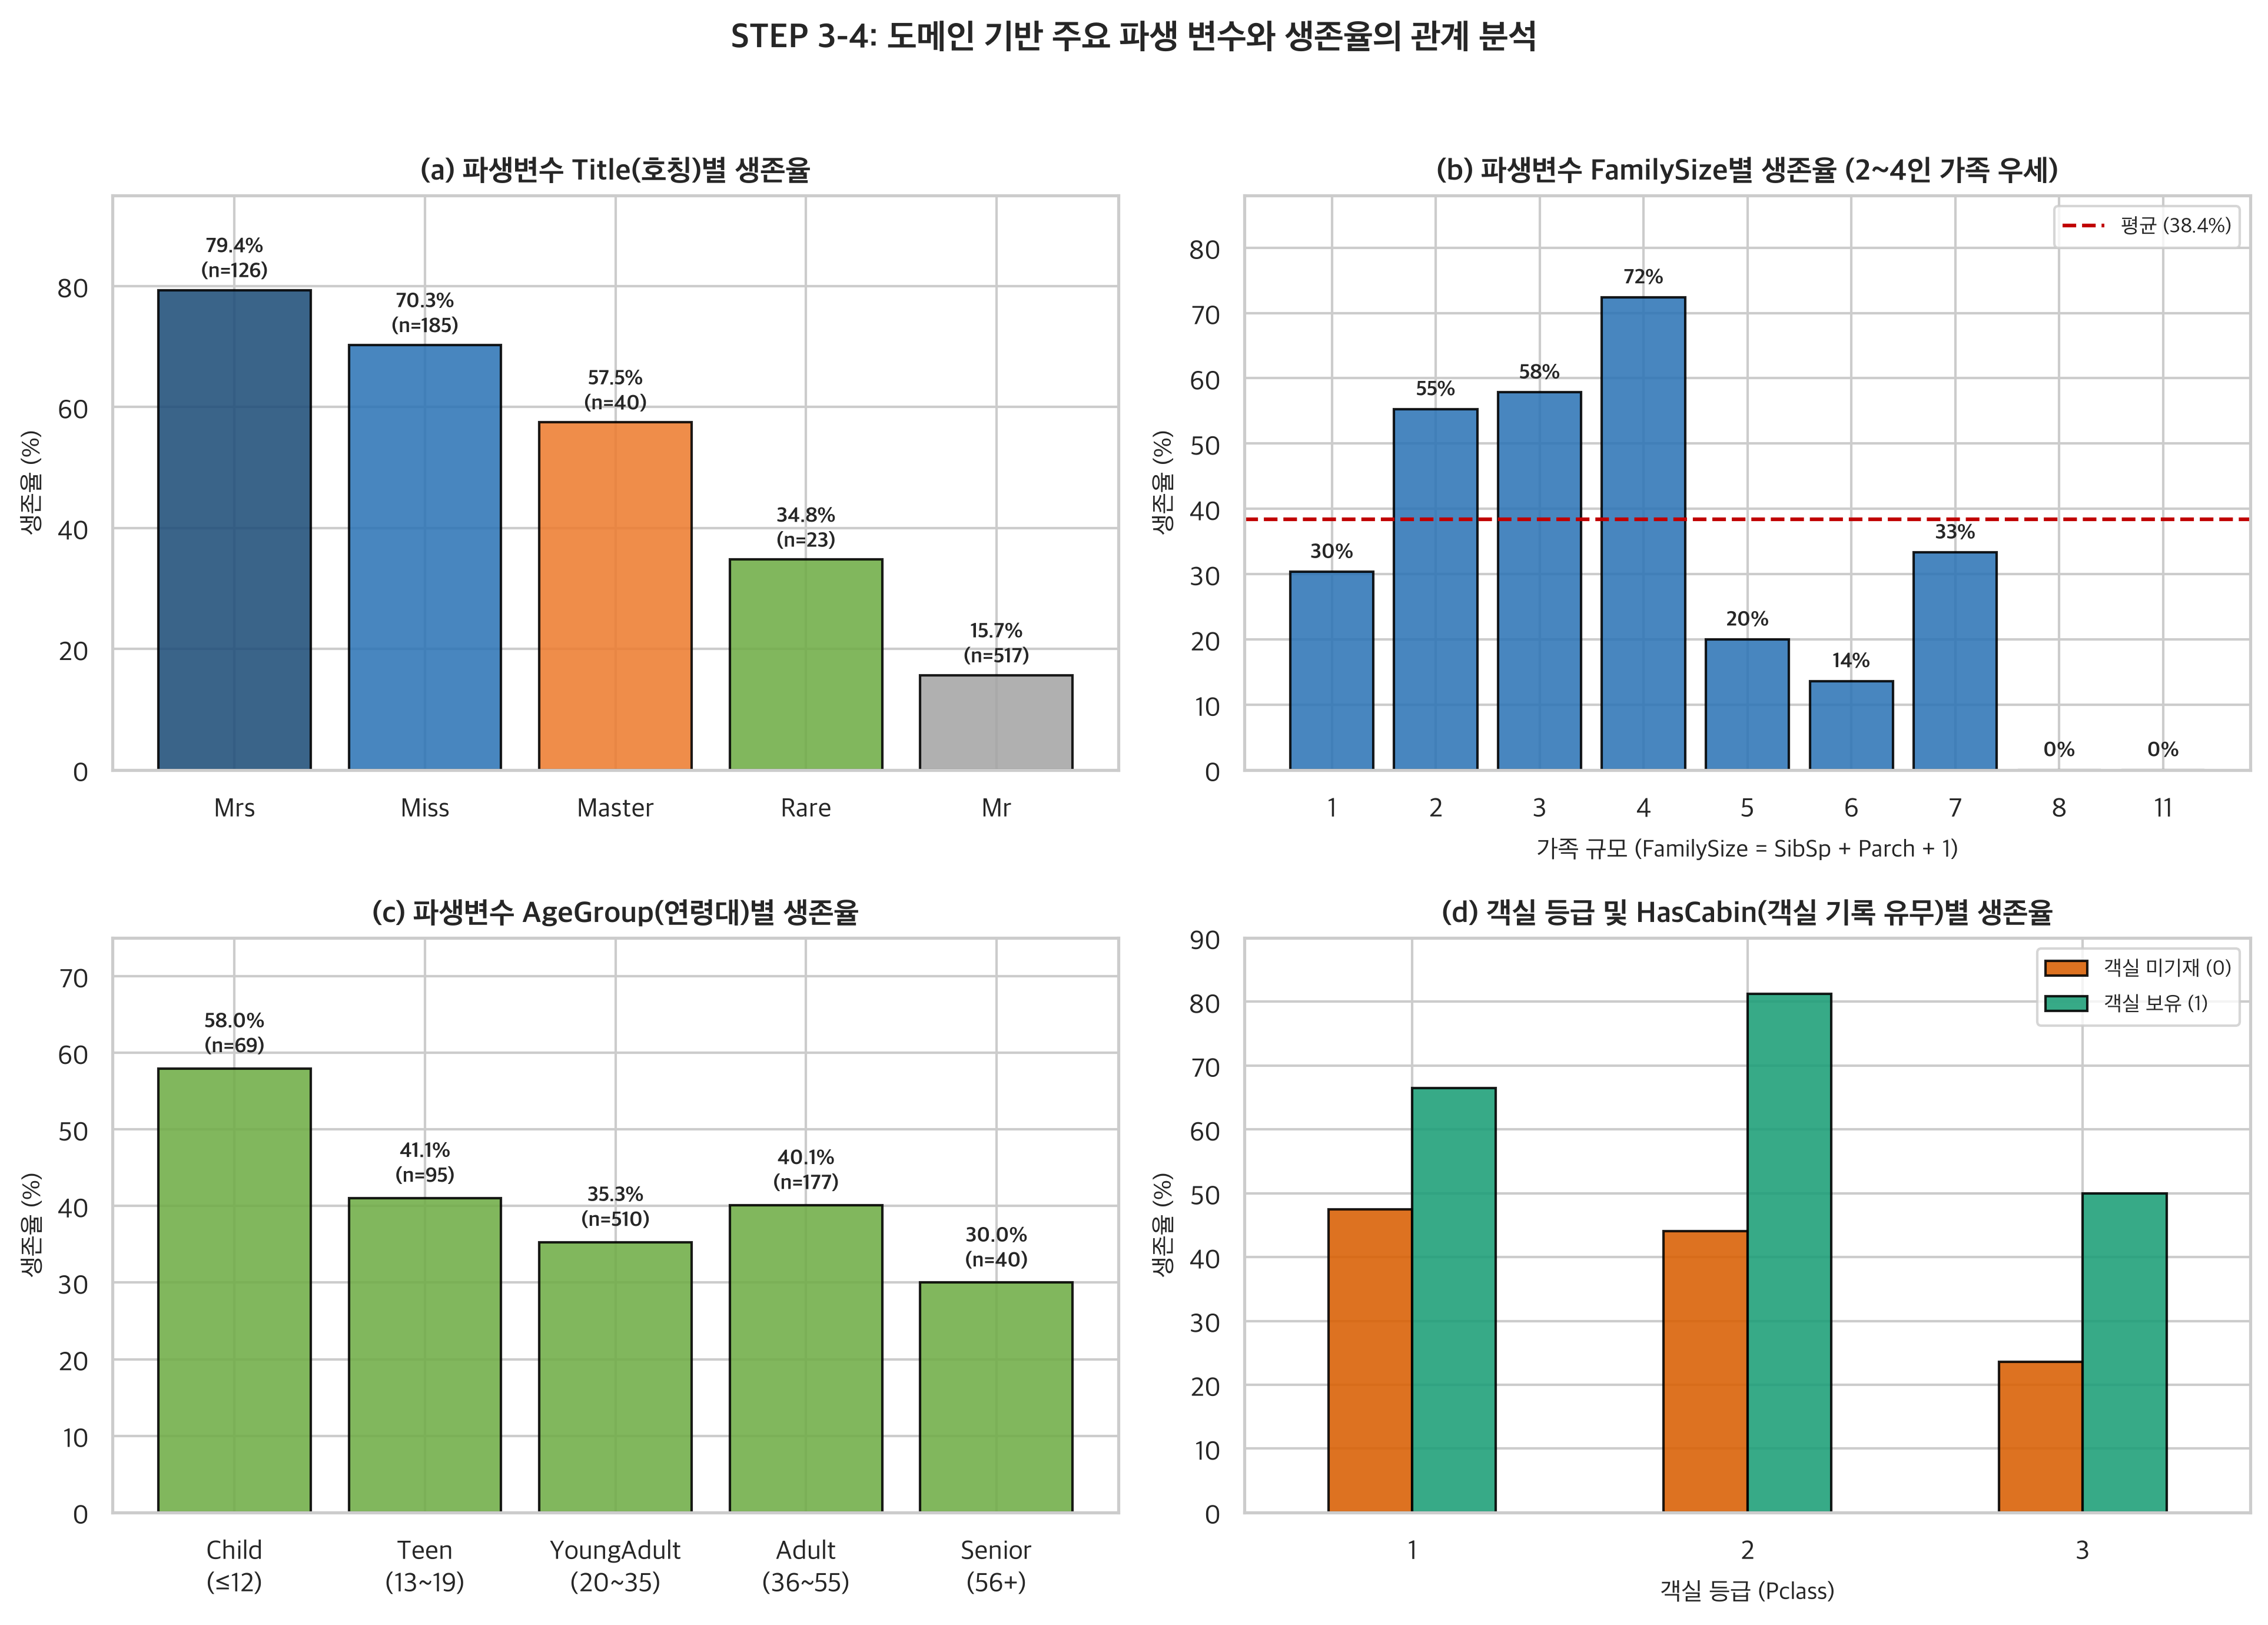

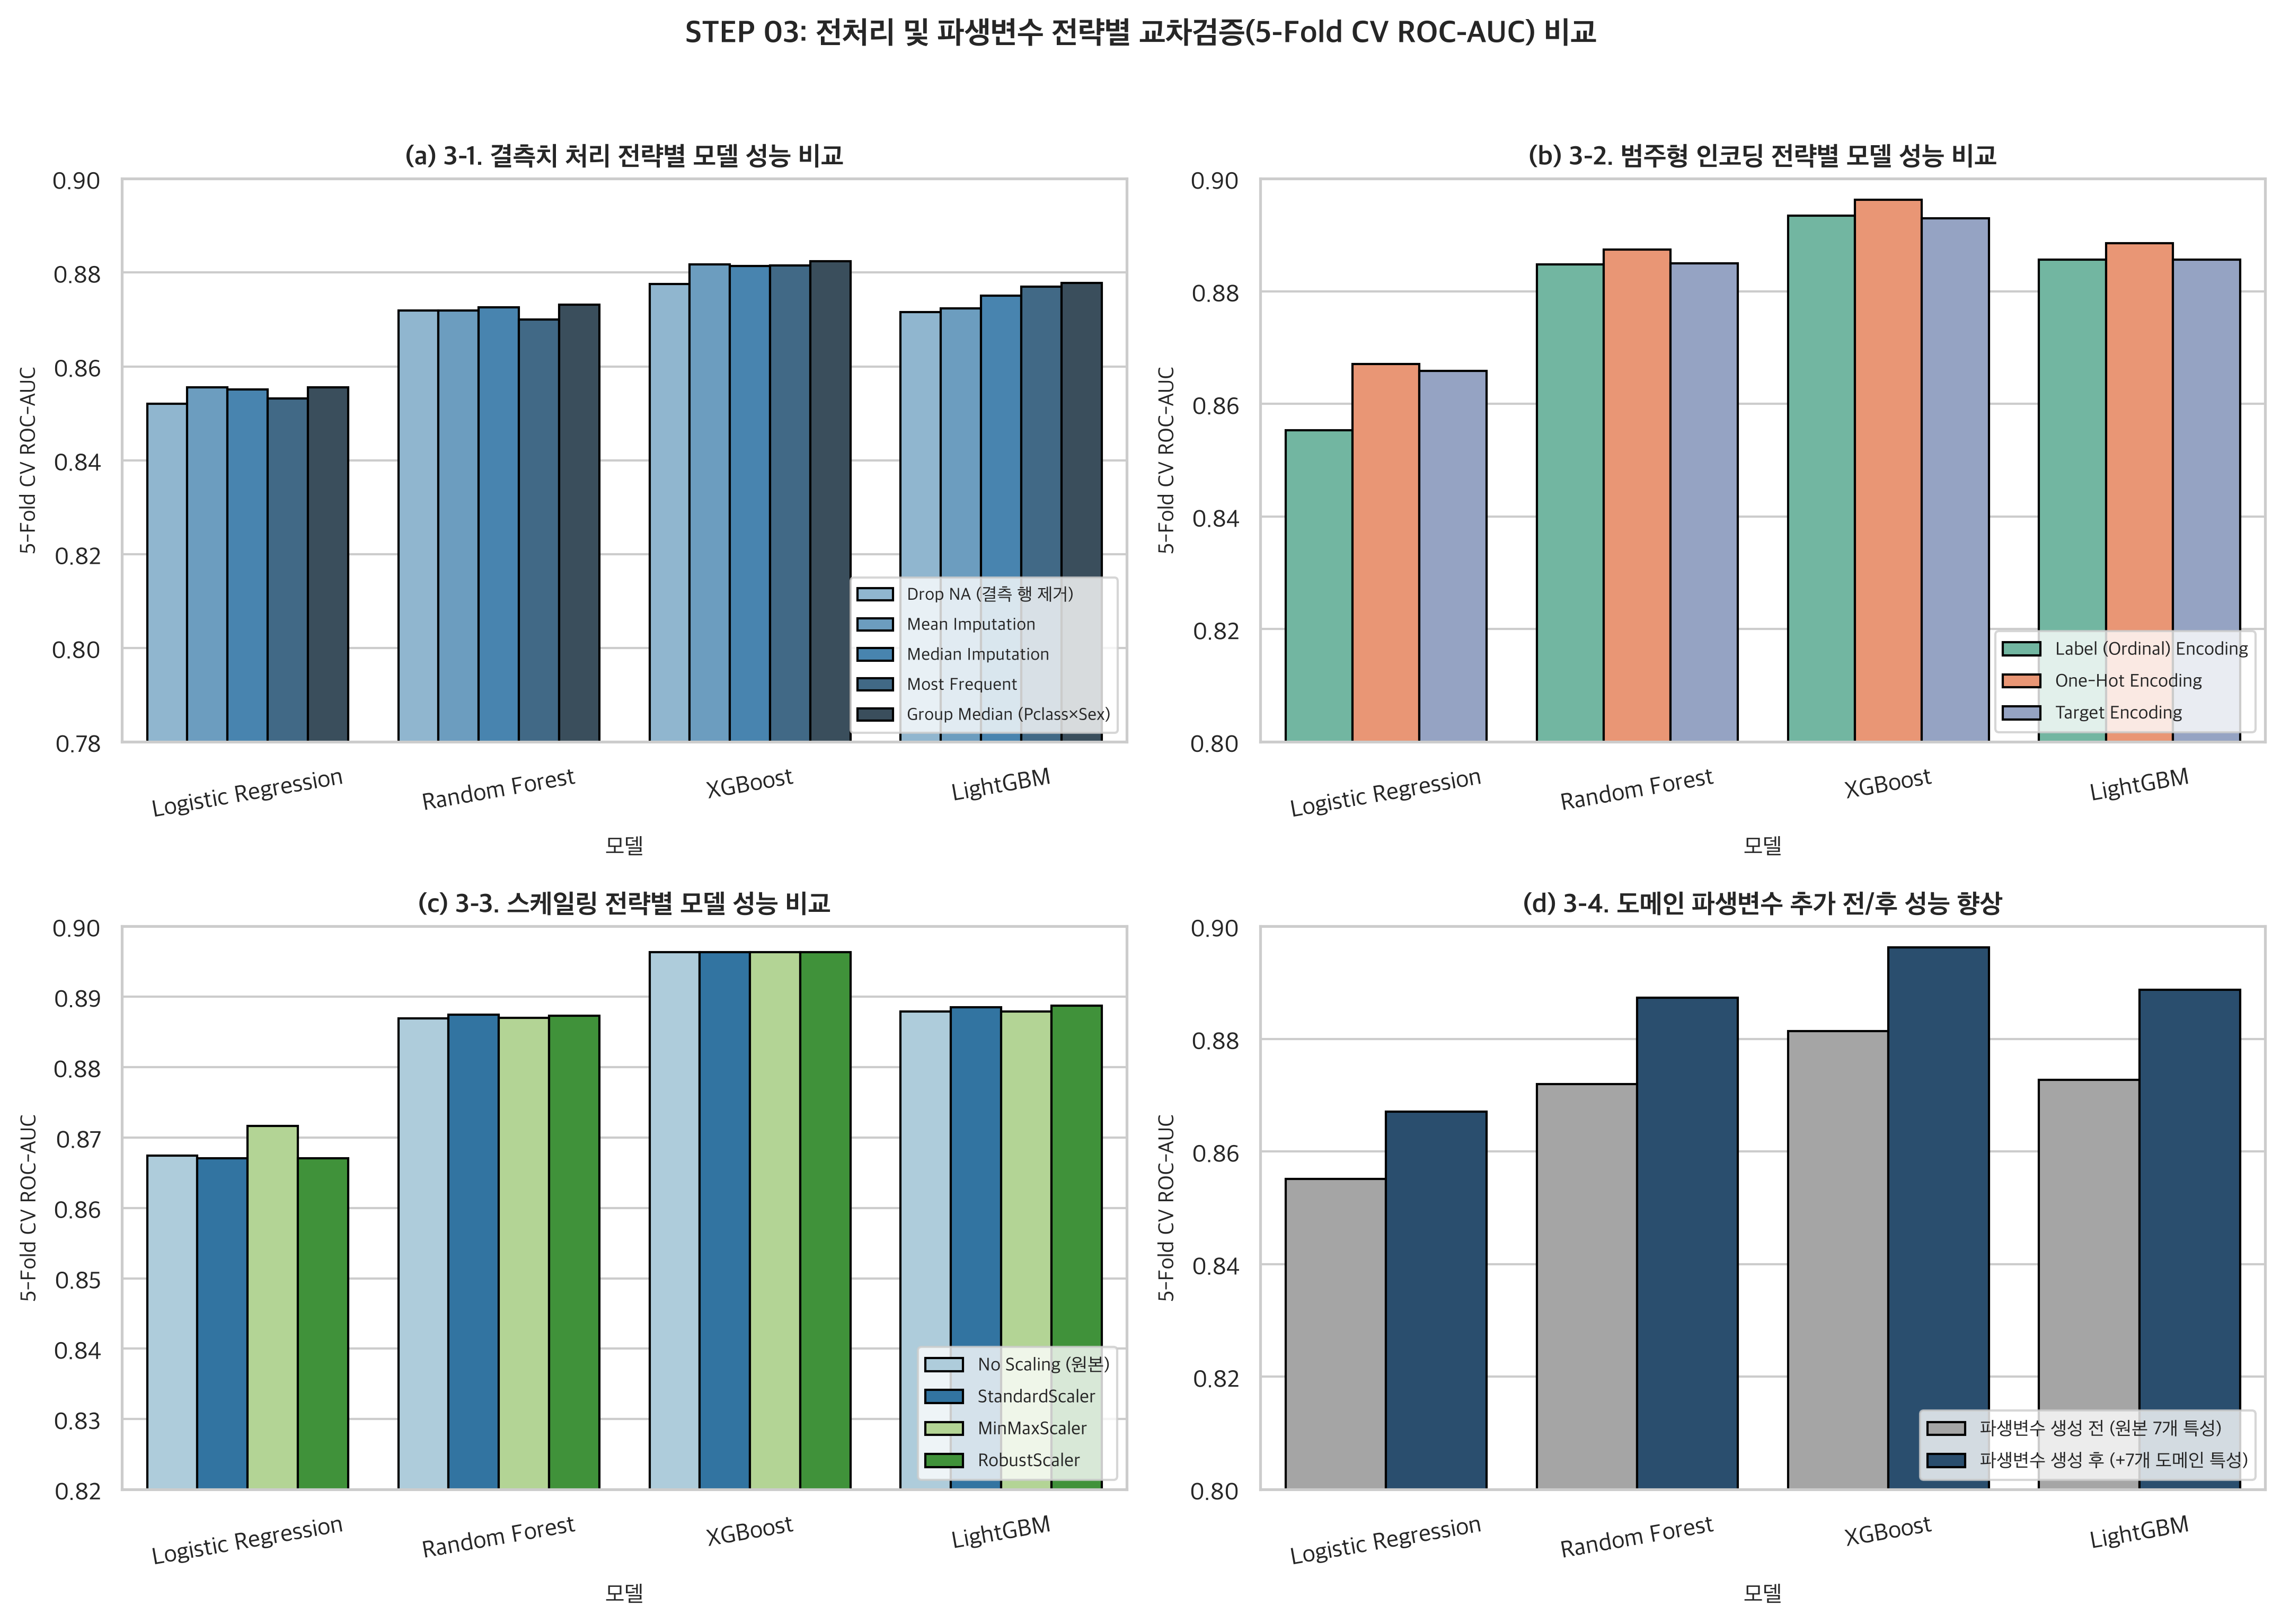

In [3]:
from src.experiments import make_preprocessor
sample_pipe = make_preprocessor(use_derived=True, num_imputer='median', encoder='onehot', scaler='robust', use_group_age=True)
print(sample_pipe)

for csv_name, title in [
    ('step03_1_imputation.csv', '[3-1] 결측치 처리 비교'),
    ('step03_2_encoding.csv', '[3-2] 범주형 인코딩 비교'),
    ('step03_3_scaling.csv', '[3-3] 스케일링 비교'),
    ('step03_4_derived_features.csv', '[3-4] 파생변수 생성 전/후 비교'),
]:
    print(f'\n=== {title} ===')
    sub = pd.read_csv(RESULTS_DIR / csv_name)
    cols = [c for c in sub.columns if not c.startswith('train_') and 'std' not in c]
    display(sub[cols].round(4))

display(Image(filename=str(FIG_DIR / 'fig06_derived_features_eda.png'), width=820))
display(Image(filename=str(FIG_DIR / 'fig07_step03_comparisons.png'), width=820))

## STEP 04. 변수 선택 (Feature Selection)
- Random Forest Importance, SelectKBest(Mutual Information), Correlation-based Selection, RFE(Recursive Feature Elimination) 4종 비교 및 제거 전/후 과적합 격차(`Train AUC - Val AUC`) 분석

,변수 선택 방법,모델,cv_roc_auc_mean,test_accuracy,test_f1,test_roc_auc,overfit_gap_roc_auc
0,"전체 변수 사용 (제거 전, 29개)",Logistic Regression,0.8682,0.8324,0.7794,0.8693,0.0146
1,"전체 변수 사용 (제거 전, 29개)",Random Forest,0.8851,0.8156,0.7402,0.8480,0.0720
2,"전체 변수 사용 (제거 전, 29개)",XGBoost,0.8971,0.7933,0.7176,0.8466,0.0787
3,"전체 변수 사용 (제거 전, 29개)",LightGBM,0.8920,0.7933,0.7176,0.8417,0.0844
4,RF Feature Importance (Top-12),Logistic Regression,0.8693,0.8101,0.7463,0.8646,0.0056
5,RF Feature Importance (Top-12),Random Forest,0.8887,0.7933,0.7259,0.8493,0.0772
6,RF Feature Importance (Top-12),XGBoost,0.8933,0.8156,0.7556,0.8456,0.0803
7,RF Feature Importance (Top-12),LightGBM,0.8874,0.7989,0.7273,0.8438,0.0877
8,SelectKBest - Mutual Info (Top-12),Logistic Regression,0.8690,0.8101,0.7463,0.8640,0.0004
9,SelectKBest - Mutual Info (Top-12),Random Forest,0.8852,0.7654,0.6818,0.8436,0.0736


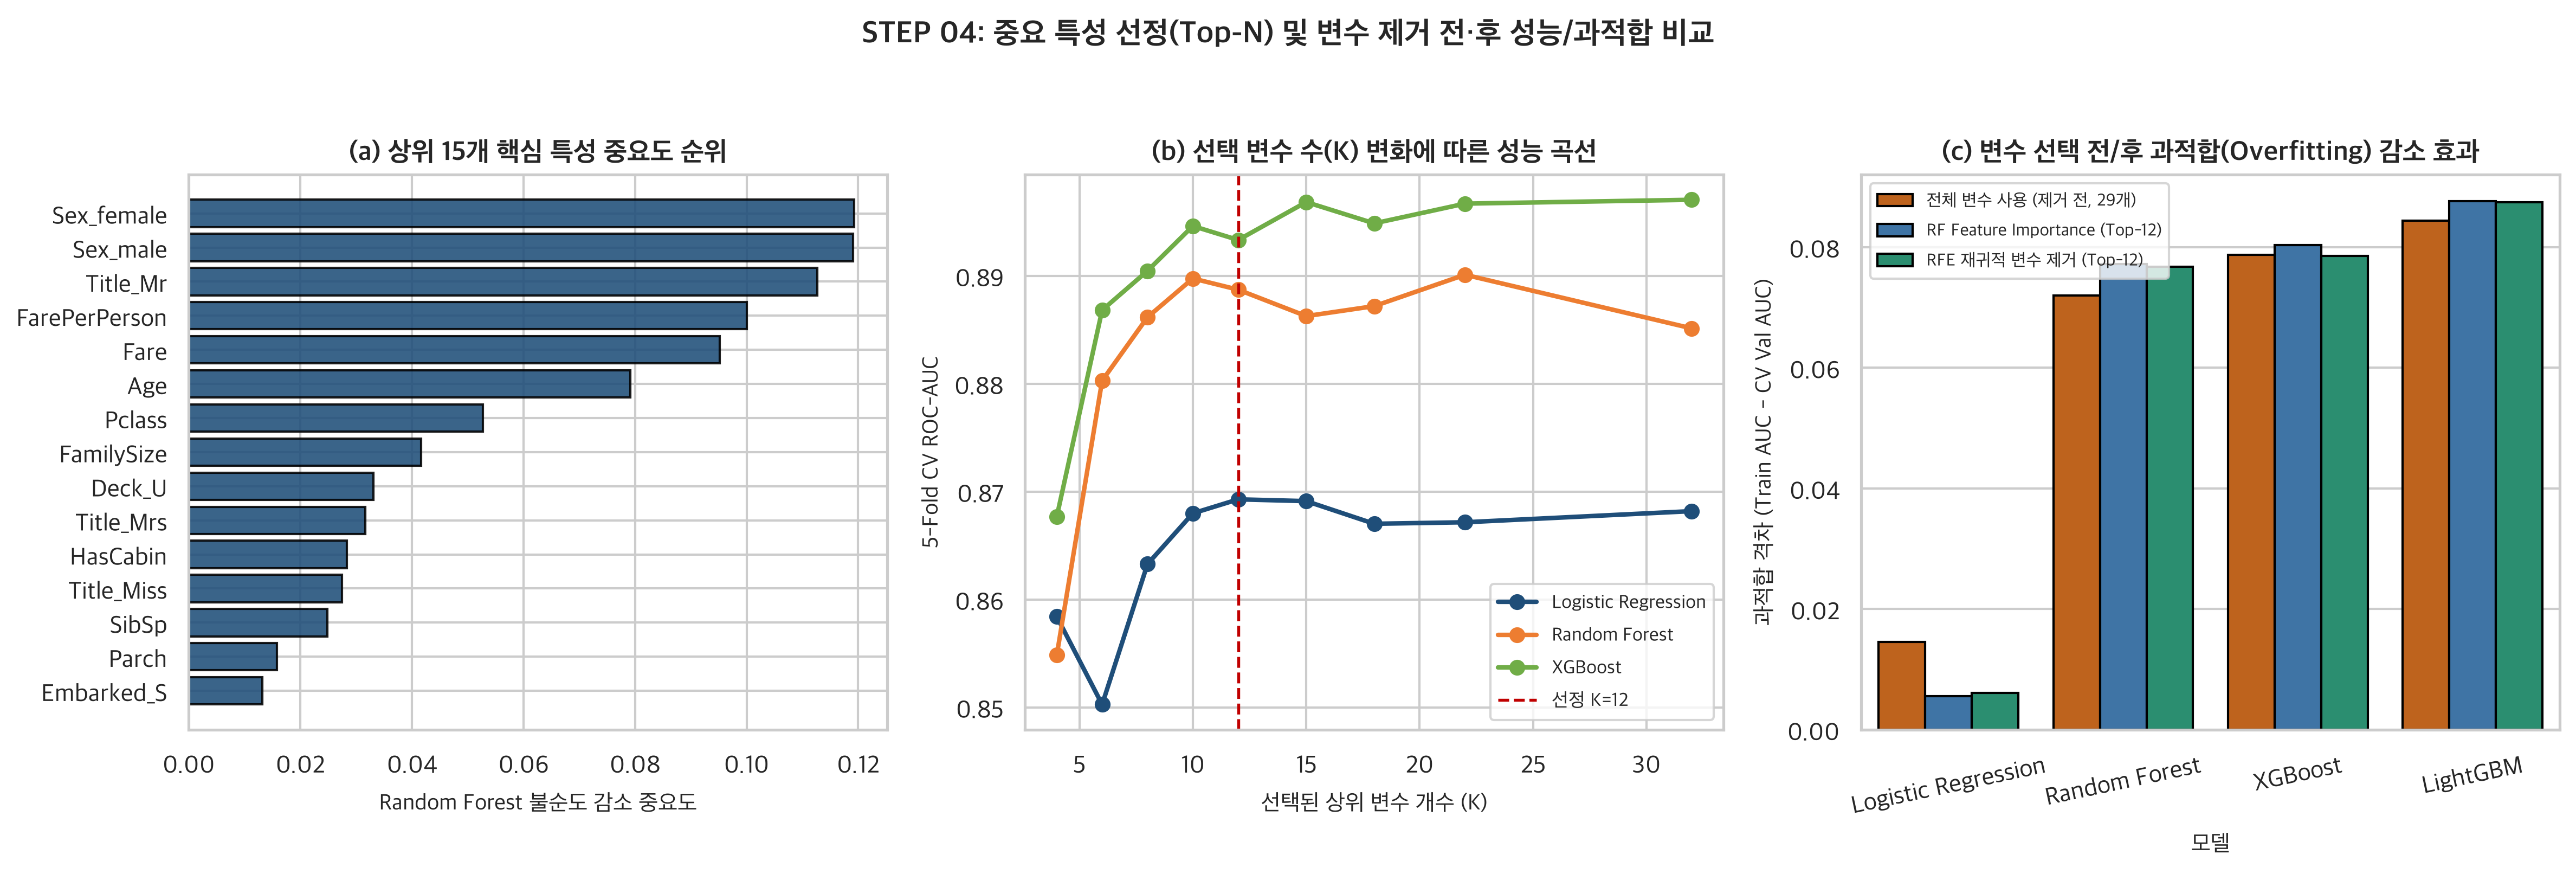

In [4]:
fs_df = pd.read_csv(RESULTS_DIR / 'step04_feature_selection.csv')
display(fs_df[['변수 선택 방법', '모델', 'cv_roc_auc_mean', 'test_accuracy', 'test_f1', 'test_roc_auc', 'overfit_gap_roc_auc']].round(4))
display(Image(filename=str(FIG_DIR / 'fig08_step04_feature_selection.png'), width=860))

## STEP 05 & 5. 필수 실험 비교표 (Base, Exp-1, Exp-2, Exp-3 + 최적 제안 Exp-4)
- 4대 분류 모델(`Logistic Regression`, `Random Forest`, `XGBoost`, `LightGBM`) × 5대 평가지표(`Accuracy`, `Precision`, `Recall`, `F1-score`, `ROC-AUC`)

,실험,결측치 처리,인코딩,스케일링,Feature Selection,모델,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,cv_roc_auc_mean
0,Base,없음,없음,없음,없음 (X),Logistic Regression,0.6480,0.5625,0.3913,0.4615,0.6742,0.7060
1,Base,없음,없음,없음,없음 (X),Random Forest,0.6536,0.5574,0.4928,0.5231,0.6640,0.7669
2,Base,없음,없음,없음,없음 (X),XGBoost,0.6760,0.6000,0.4783,0.5323,0.6648,0.7772
3,Base,없음,없음,없음,없음 (X),LightGBM,0.6816,0.6071,0.4928,0.5440,0.6591,0.7770
4,Exp-1,Mean,One-Hot,Standard,X,Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8705,0.8674
5,Exp-1,Mean,One-Hot,Standard,X,Random Forest,0.8101,0.7869,0.6957,0.7385,0.8481,0.8860
6,Exp-1,Mean,One-Hot,Standard,X,XGBoost,0.7933,0.7667,0.6667,0.7132,0.8450,0.8951
7,Exp-1,Mean,One-Hot,Standard,X,LightGBM,0.7821,0.7500,0.6522,0.6977,0.8352,0.8886
8,Exp-2,Median,Label,MinMax,O (Top-10),Logistic Regression,0.8045,0.7656,0.7101,0.7368,0.8509,0.8543
9,Exp-2,Median,Label,MinMax,O (Top-10),Random Forest,0.7933,0.7500,0.6957,0.7218,0.8470,0.8855


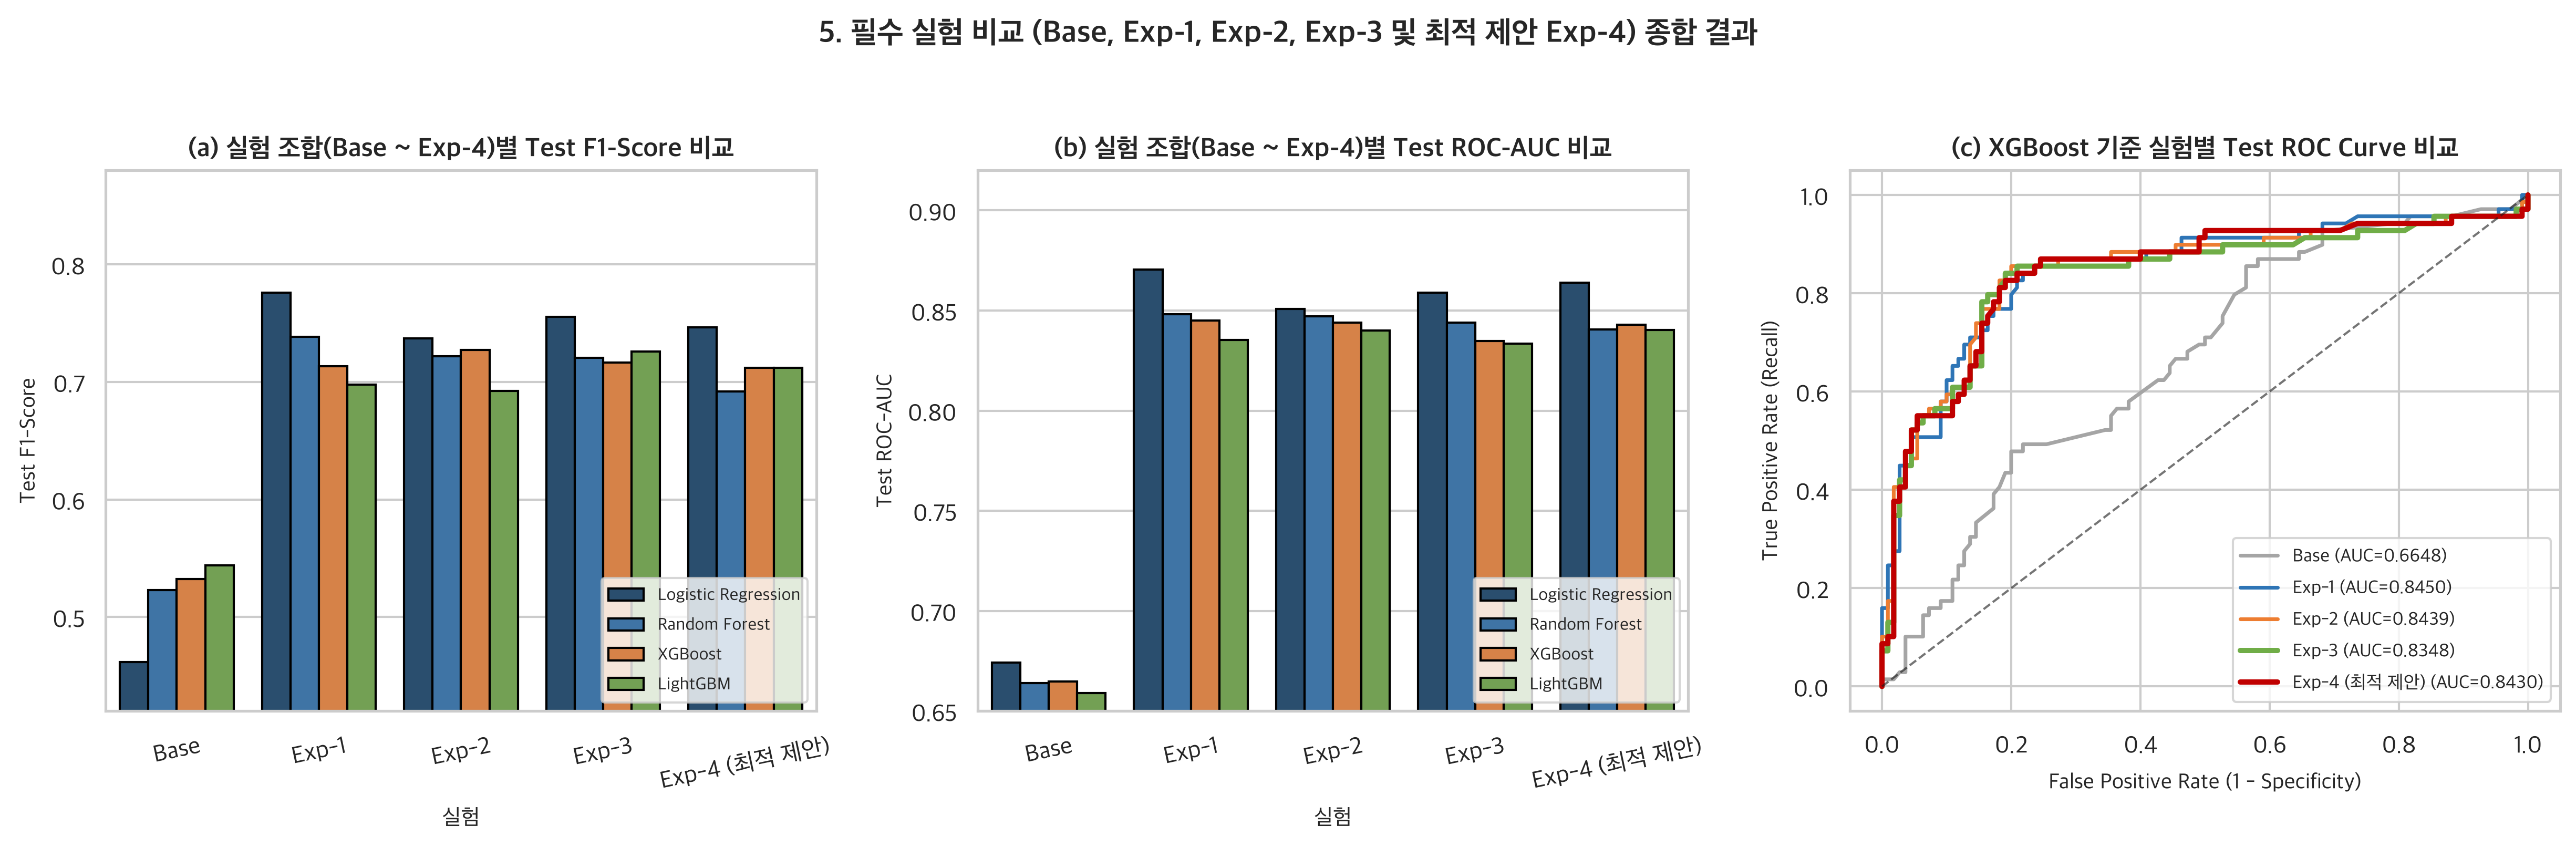

In [5]:
mand_df = pd.read_csv(RESULTS_DIR / 'step05_mandatory_comparison.csv')
cols_show = ['실험', '결측치 처리', '인코딩', '스케일링', 'Feature Selection', '모델',
             'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc', 'cv_roc_auc_mean']
display(mand_df[cols_show].round(4))
display(Image(filename=str(FIG_DIR / 'fig09_mandatory_exp_comparison.png'), width=860))

## 8. 추가 가산점 심화 분석 (GridSearchCV, 다각도 Feature Importance, SHAP, LIME, AutoML)

=== GridSearchCV 튜닝 결과 ===


,모델,튜닝 전 CV AUC,튜닝 후 CV AUC,튜닝 전 Test AUC,튜닝 후 Test AUC,튜닝 후 Accuracy,튜닝 후 Precision,튜닝 후 Recall,튜닝 후 F1,최적 하이퍼파라미터
0,Logistic Regression,0.8693,0.8693,0.8640,0.8646,0.8101,0.7692,0.7246,0.7463,"{'clf__C': 1.0, 'select__max_features': 12}"
1,Random Forest,0.8860,0.8910,0.8404,0.8489,0.7821,0.7344,0.6812,0.7068,"{'clf__max_depth': 10, 'clf__min_samples_leaf'..."
2,XGBoost,0.8949,0.8984,0.8430,0.8495,0.7877,0.7541,0.6667,0.7077,"{'clf__colsample_bytree': 0.85, 'clf__learning..."
3,LightGBM,0.8856,0.8935,0.8402,0.8337,0.7877,0.7541,0.6667,0.7077,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."


=== FLAML AutoML 비교 결과 ===


,비교 방식,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,"FLAML AutoML (원본 변수만 사용, Best=xgboost)",0.8809,0.8156,0.8103,0.6812,0.7402,0.8385
1,"FLAML AutoML (도메인 파생변수 결합, Best=xgboost)",0.8832,0.7821,0.7344,0.6812,0.7068,0.8325
2,수동 설계 FE Pipeline + GridSearchCV (XGBoost),0.8984,0.7877,0.7541,0.6667,0.7077,0.8495


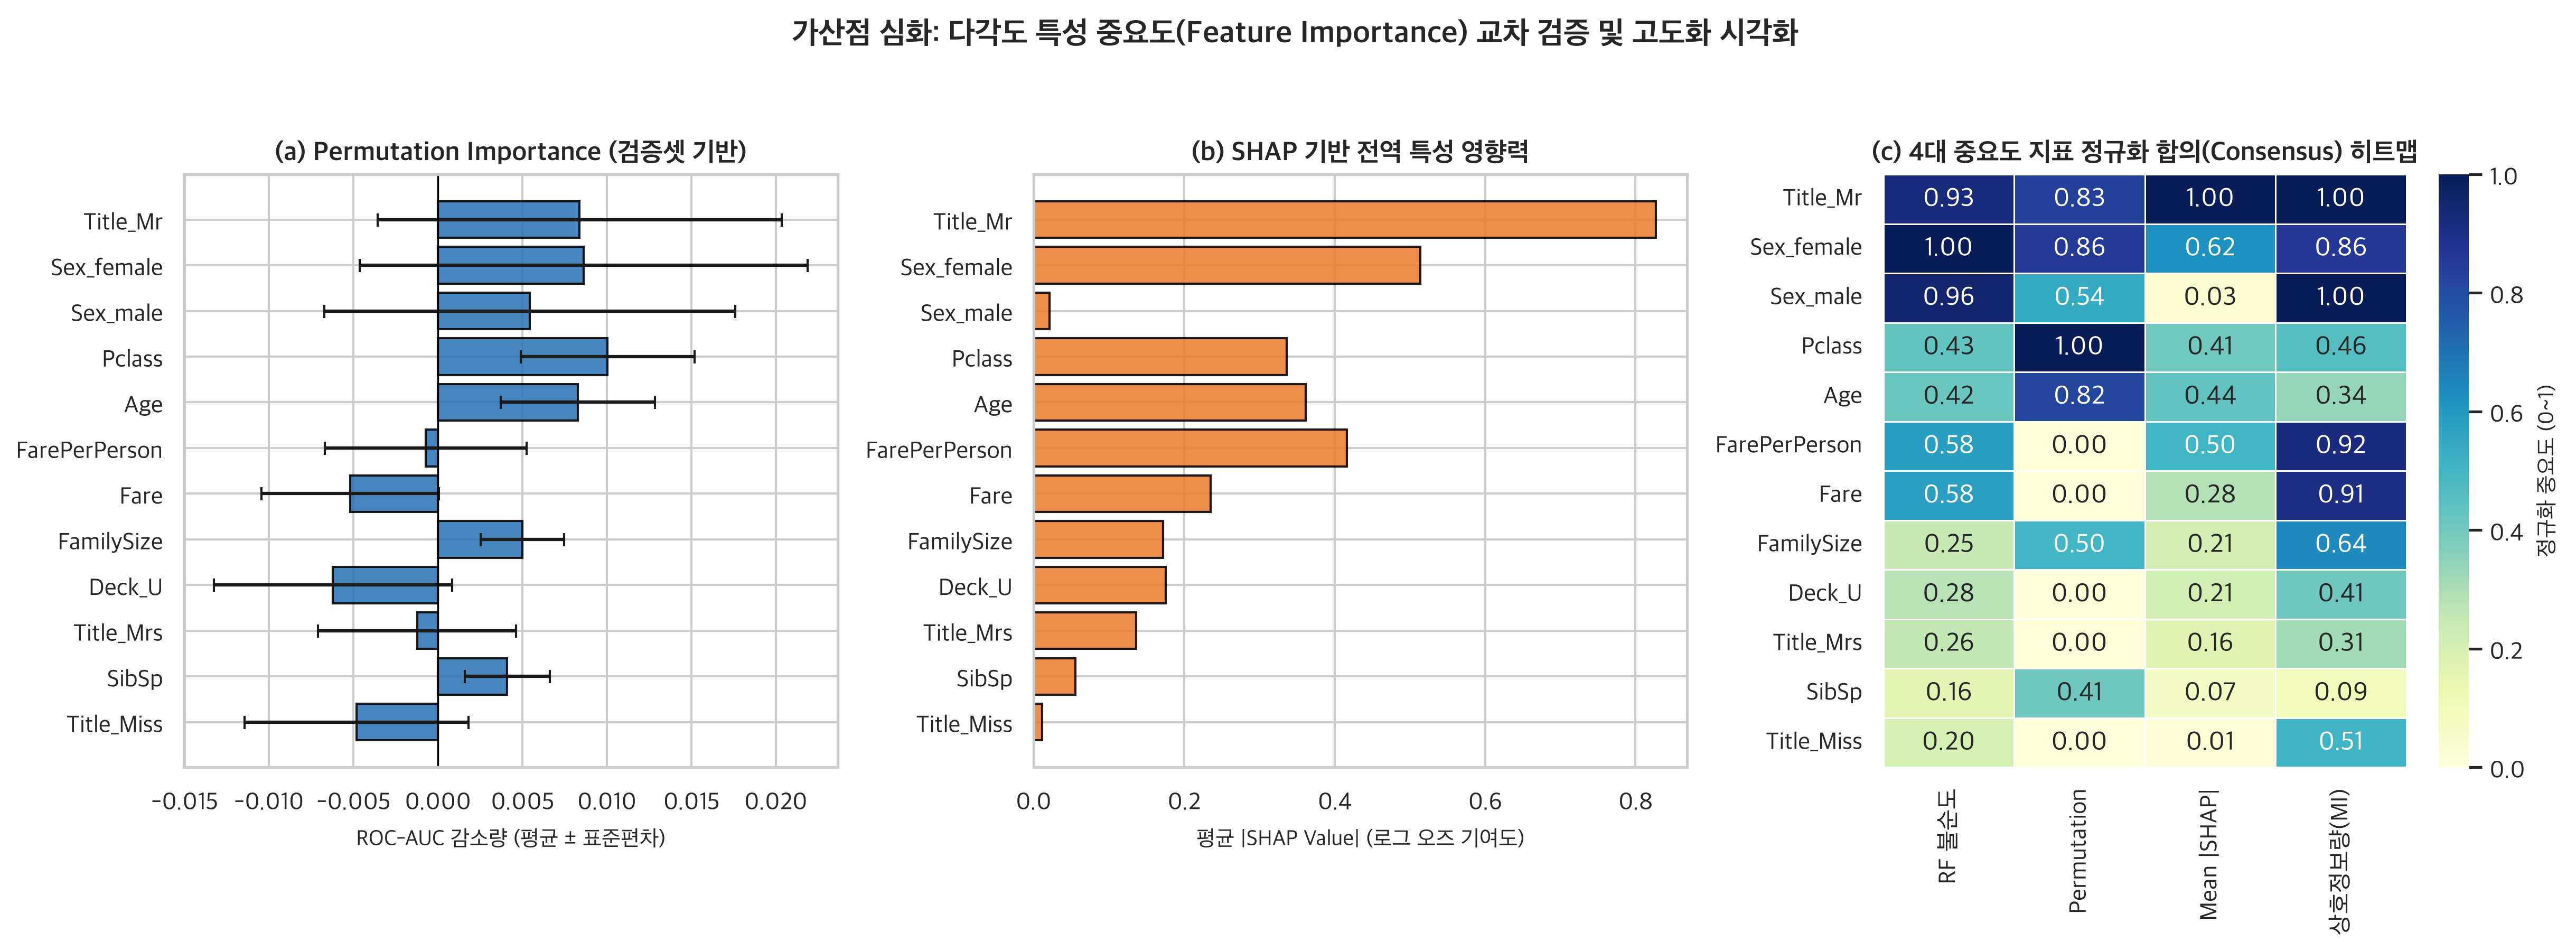

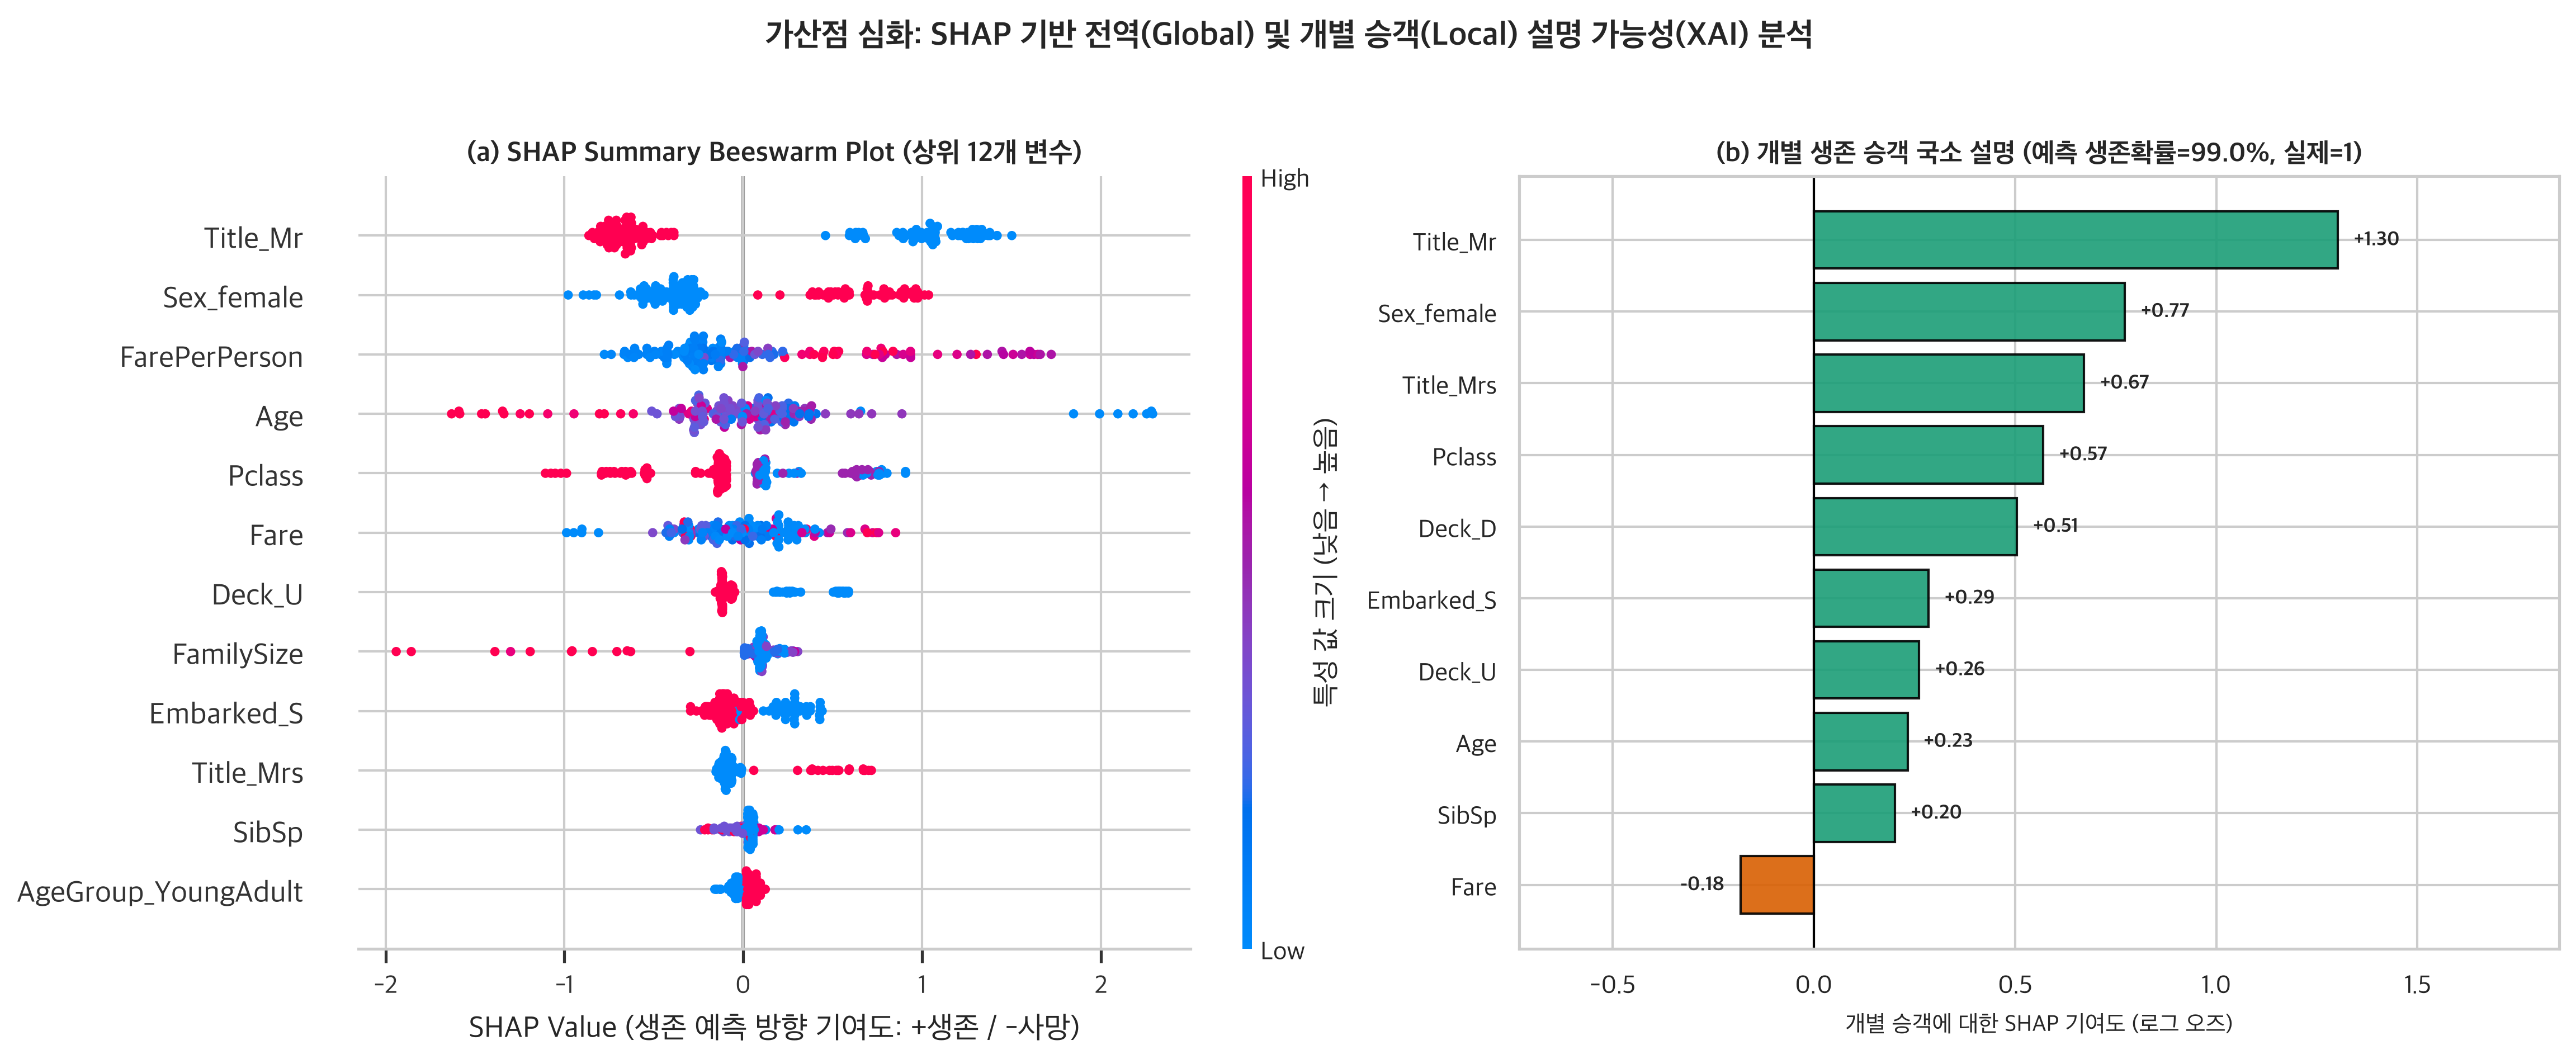

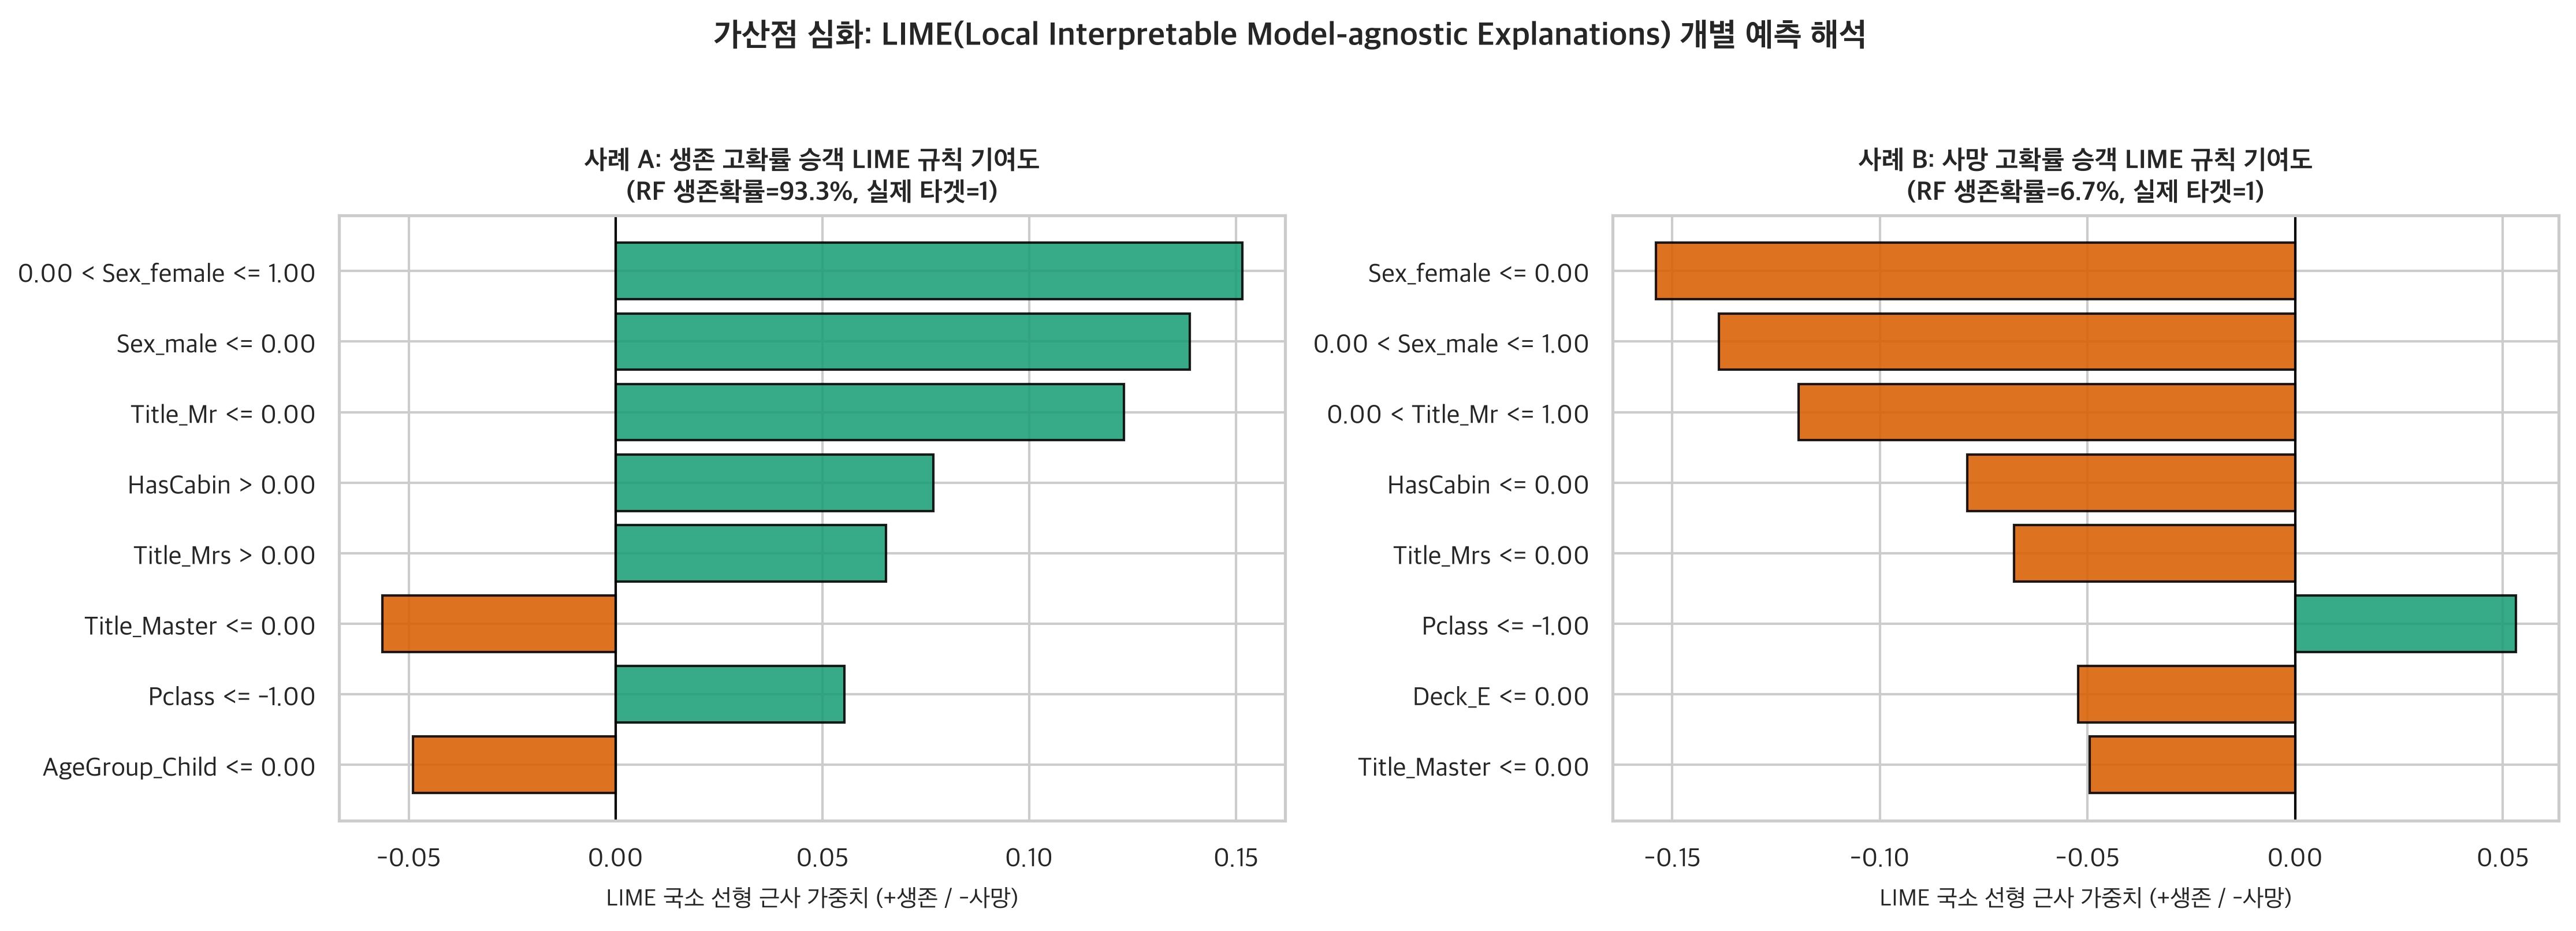

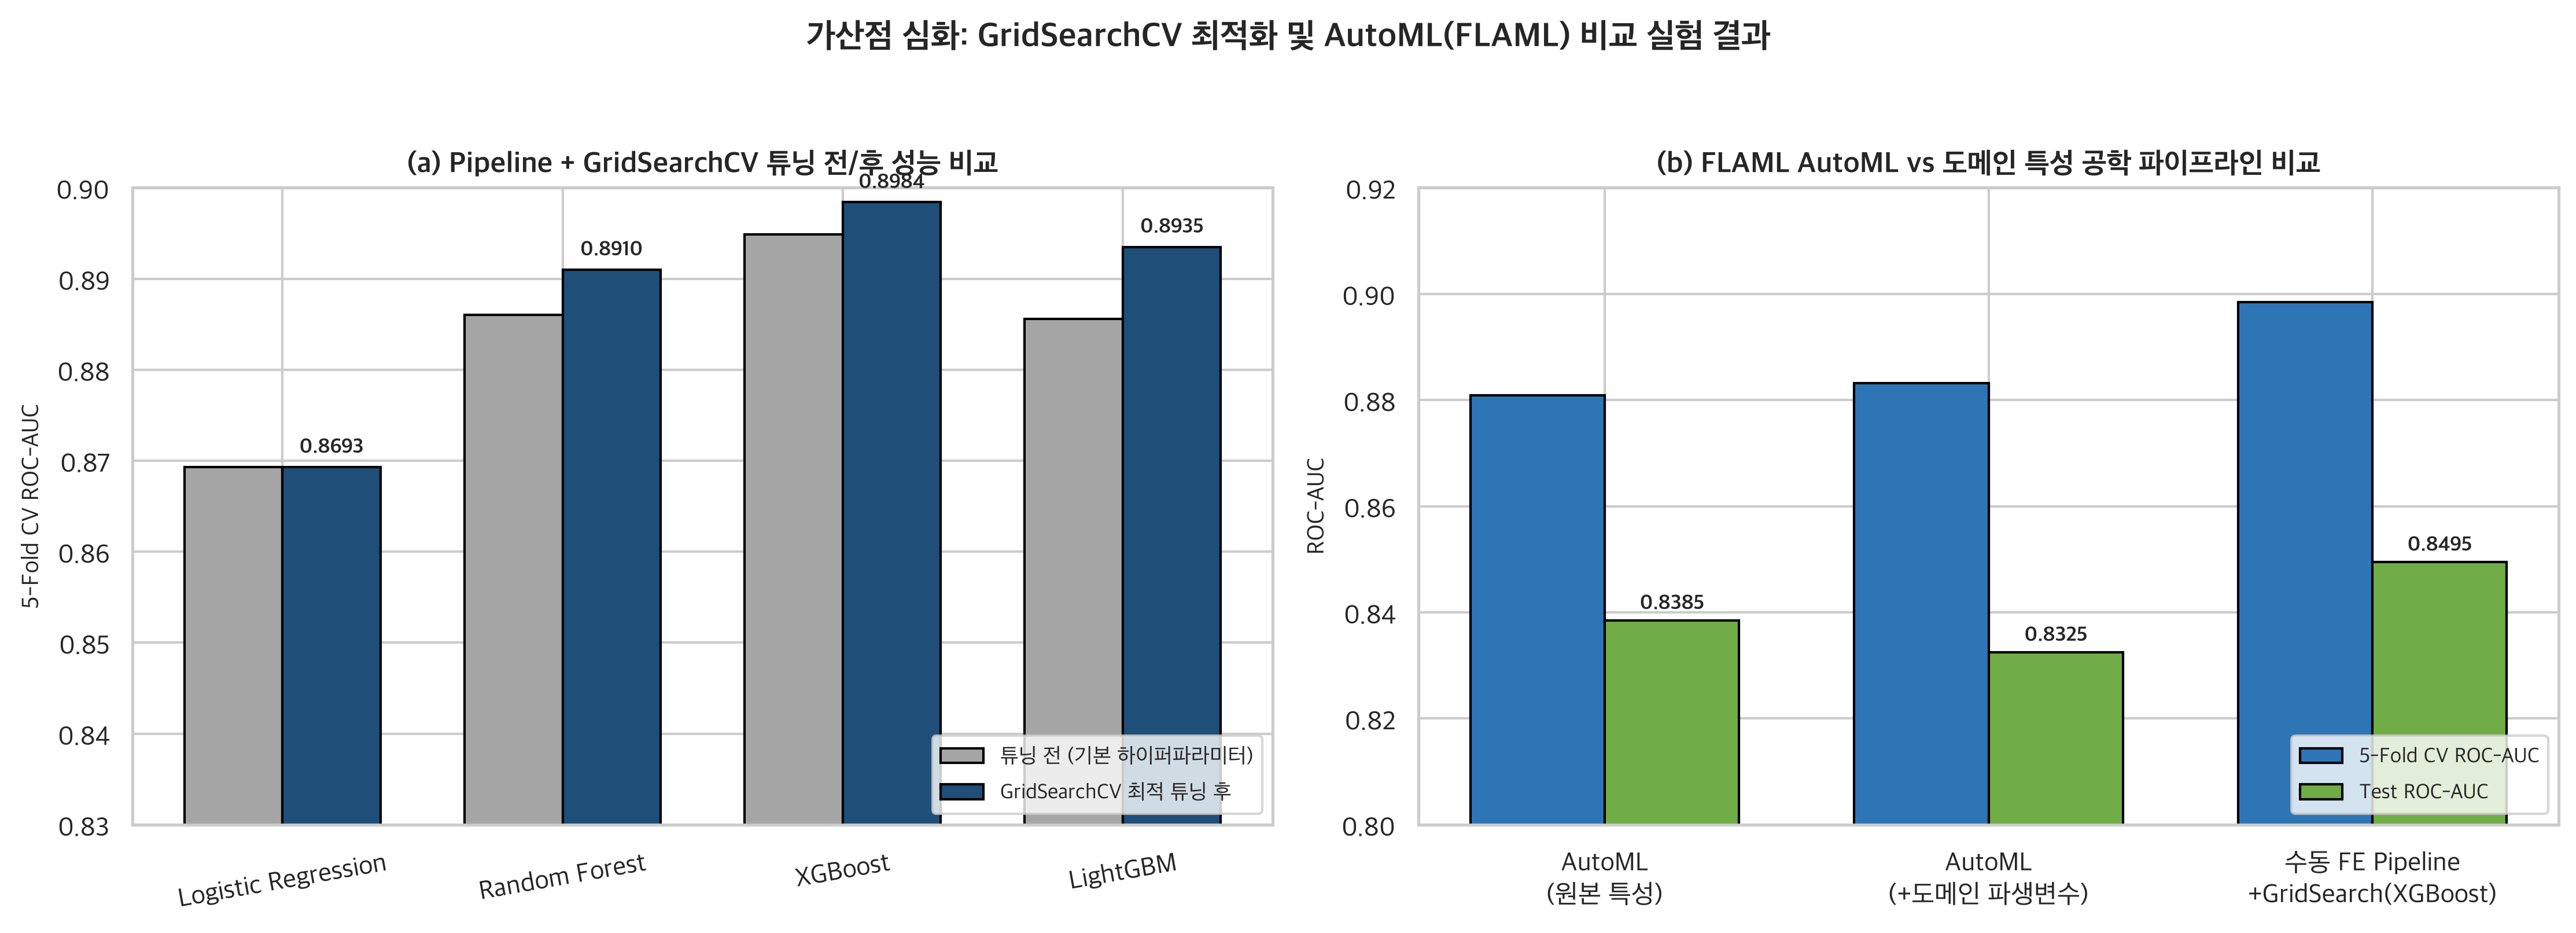

In [6]:
gs_df = pd.read_csv(RESULTS_DIR / 'bonus_gridsearch.csv')
automl_df = pd.read_csv(RESULTS_DIR / 'bonus_automl_comparison.csv')
print('=== GridSearchCV 튜닝 결과 ===')
display(gs_df)
print('=== FLAML AutoML 비교 결과 ===')
display(automl_df)
for fig_name in [
    'fig10_advanced_feature_importance.png',
    'fig11_shap_analysis.png',
    'fig12_lime_explanations.png',
    'fig13_automl_and_gridsearch.png',
]:
    display(Image(filename=str(FIG_DIR / fig_name), width=860))